# Chapter 2: Fundamentals of Quantum Computation

*This chapter reviews the basic concepts of quantum computing needed for the rest of the book. We define qubits and quantum states using Dirac notation and the Bloch sphere representation. Elementary quantum gates (Pauli rotations, Hadamard, phase gate, CNOT) and universal gate sets are introduced, along with quantum circuits and circuit diagrams. Key principles such as superposition and entanglement are explained. Finally, we cover measurement postulates, decoherence, and simple quantum protocols (like teleportation and superdense coding). These protocols exemplify how quantum information processing differs fundamentally from classical computing.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Quantum computing in a nutshell

A quantum computer is a well-controlled, out-of-equilibrium quantum
many-body system that we intend to use to perform a calculation. Such a
system can be described at several levels, from the underlying physics,
usually expressed through a Hamiltonian with its energies and time scales,
up to the abstract representation used to formulate quantum algorithms,
the so-called *gate-based quantum computer*. This chapter is about that abstract level: the states a quantum
computer can be in, the operations we can perform on them, and what we can
learn by measuring them. The chapters that follow build on these notions
when they map many-body Hamiltonians onto qubits (Chapter 4),
simulate their time evolution (Chapter 5) and extract
eigenvalues from them (Chapters 6--8).

The gate-based quantum computer is defined as follows. We have a set of $N$
two-level systems, called quantum bits or *qubits* (for
instance the spin of an electron, or two selected levels of a
superconducting circuit), each of which can be in the states $\vert 0\rangle$
and $\vert 1\rangle$. The most general state of the quantum computer has the
form

$$
\vert\Psi\rangle = \sum_{i_1i_2\cdots i_N} \Psi_{i_1i_2\cdots i_N} \vert i_1i_2\cdots i_N\rangle,\tag{2.1}
$$

where the sum runs over all qubit values $i_a \in \{0,1\}$, and
$\vert i_1i_2\cdots i_N\rangle$ is a shorthand for the tensor product
$\vert i_1\rangle\otimes \vert i_2\rangle\otimes\cdots\otimes\vert i_N\rangle$,
to be defined in Section *Tensor products*. The tensor
$\Psi_{i_1i_2\cdots i_N}$ can be thought of as a large vector containing
$2^N$ complex numbers. The potential capabilities of quantum computers stem
from the fact that this vector is exponentially large and, once
$N\gtrsim 50$, cannot even be stored in a classical computer.

When one operates a quantum computer, one initializes it in a simple
state $\vert \Psi^{(0)}\rangle$, usually
$\vert \Psi^{(0)}\rangle = \vert 000\cdots 0\rangle$, and the state then
evolves according to the Schr\"odinger equation, which transforms
$\vert \Psi^{(n)}\rangle$ into
$\vert \Psi^{(n+1)}\rangle = U^{(n)} \vert \Psi^{(n)}\rangle$, with the
evolution operator

$$
U^{(n)} = T\exp\left[-i\int_{t_n}^{t_{n+1}} \ud{t}\, H(t)\right],\tag{2.2}
$$

where $T$ is the time-ordering operator and $H(t)$ is the Hamiltonian of the
system (we set $\hbar=1$ throughout this book unless stated otherwise). In
physics one starts from $H(t)$. In quantum computing one starts instead from
the evolution operators $U^{(n)}$, assuming that somebody else has worked
out how to engineer the appropriate Hamiltonians. The different evolution
operators that one uses are called *gates* and fall into
two main categories, depending on whether they act on a single qubit or on
two qubits.

A single-qubit gate is a $2\times 2$ unitary matrix $U$ acting on one
qubit, $U\vert i\rangle = \sum_j U_{ji}\vert j\rangle$. In terms of the
full state $\Psi^{(n)}$, a single-qubit gate on qubit $a$ acts as

$$
\Psi_{i_1i_2\cdots i_N}^{(n+1)} = \sum_{i'_a} U_{i_ai'_a}
\Psi_{i_1\cdots i_{a-1}i'_a i_{a+1}\cdots i_N}^{(n)},\tag{2.3}
$$

and a two-qubit gate on qubits $a$ and $b$ is a $4\times 4$ unitary matrix
which transforms the state as

$$
\Psi_{i_1i_2\cdots i_N}^{(n+1)} = \sum_{i'_a,i'_b} U_{i_ai_b,i'_ai'_b}
\Psi_{i_1\cdots i'_a \cdots i'_b \cdots i_N}^{(n)}.\tag{2.4}
$$

Depending on the hardware, some gates are easier to implement than others,
but a small set of them suffices to build any unitary operation on the
$2^N$-dimensional space, as we discuss in Section *Universal gate sets*.

The last ingredient of the gate model is *measurement*.
When qubit $a$ is measured, it returns the value $\alpha\in\{0,1\}$ with
probability

$$
P_\alpha = \sum_{i_1\cdots i_{a-1} i_{a+1}\cdots i_N} \left|
\Psi_{i_1\cdots i_{a-1} \alpha i_{a+1}\cdots i_N}^{(n)} \right|^2,\tag{2.5}
$$

and the state of the computer becomes

$$
\Psi_{i_1\cdots i_N}^{(n)}\rightarrow
\delta_{i_a,\alpha} \frac{1}{\sqrt{P_\alpha}}
\Psi_{i_1\cdots i_{a-1} \alpha i_{a+1}\cdots i_N}^{(n)}.\tag{2.6}
$$

That is essentially it. Equations (2.1)--(2.6)
describe completely what a gate-based quantum computer does, and the field
of quantum algorithms consists of using these rules to perform useful
computations. In a nutshell, a quantum computer allows one to perform a
subset of linear algebra, namely matrix-vector multiplications with very
special matrices (the gates, which act only on a few indices and belong to a
fixed set of unitary matrices) on exponentially large vectors. The appeal
of quantum computers clearly comes from the exponentially large size of
these vectors.

There is however a strong downside: at the end of the calculation one does
not hold the exponentially large vector of $2^N$ amplitudes, but only a much
smaller amount of information, namely $N$ bits drawn from the distribution
$|\Psi_{i_1\cdots i_N}|^2$. This is one of the two Achilles' heels of
quantum computing, often referred to as the input/output
bottleneck. A second caveat is that the
largest part of the $2^N$-dimensional Hilbert space will remain forever
inaccessible, to quantum computers as well as to classical methods. This
follows from a simple counting argument. Suppose the quantum circuit
consists of $D$ layers of gates ($D$ being the depth of the circuit), that
every layer is packed with as many gates as possible, and that each gate is
parametrized by a few angles. The dimension of the manifold of states that
such circuits can reach is then $\bigO(DN)$, which for any realistic depth
is vastly smaller than $2^N$. With $N=100$ qubits the Hilbert space has
dimension $2^{100}\approx 10^{30}$; even with a depth $D=10^6$ the reachable
manifold has twenty orders of magnitude fewer degrees of freedom. The
question is therefore whether the reachable subspace contains the
*relevant* part of Hilbert space, and, conversely, whether the relevant
part is amenable to classical simulation. Much of the discussion of
variational algorithms in Chapter 7 revolves around this
question; the so-called barren plateaus, for instance, have been traced back
to the fact that most states in the $\bigO(DN)$-dimensional manifold are
essentially featureless [Larocca2025].

To make all of the above precise we need a modest amount of linear
algebra, which we now review in the language of quantum mechanics. Readers
who want a more thorough treatment, including norms, matrix factorizations
and the numerical eigenvalue algorithms that we lean on throughout the
book, will find it in Appendix B. Standard references for
the material of this chapter are the books of Nielsen and Chuang
[NielsenChuang], Scherer [Scherer2019] and, for readers who
prefer to learn by programming, Hundt [Hundt2022].


## Linear algebra in Dirac notation

### Vectors, inner and outer products

Vectors, matrices and higher-order tensors are written in boldface, with
lower-case letters for vectors and upper-case letters for matrices; see
Section *Notations and conventions* of the appendix for the full set of
conventions. A vector with $n$ complex components is written as

\begin{equation*}
\vec{x} = \begin{bmatrix} x_0\\ x_1 \\ \vdots \\ x_{n-1} \end{bmatrix},\qquad
\vec{x}^{\dagger} = \begin{bmatrix} x_0^* & x_1^* & \dots & x_{n-1}^* \end{bmatrix},\tag{2.7}
\end{equation*}

where the dagger denotes the Hermitian conjugate, the complex conjugate of
the transpose. We start counting from zero, so that the first component
$x_0$ multiplies the basis state $\vert 0\rangle$ below and the index of a
component agrees with the integer encoded by a bit string of qubits.

Throughout the book we use Dirac's *bra-ket*
notation and replace the boldfaced vector by a ket and its Hermitian
conjugate by a bra,

$$
\vec{x} = \vert x \rangle,\qquad \vec{x}^{\dagger} = \langle x \vert .
$$

The inner product of two vectors of the same length is

$$
\langle y \vert x\rangle = \sum_{i=0}^{n-1} y_i^*x_i,\tag{2.9}
$$

so that $\langle x\vert x\rangle=\sum_i|x_i|^2$ is real and non-negative,
while in general

$$
\langle x\vert y\rangle^* = \langle y \vert x\rangle .\tag{2.10}
$$

As an example, for $\vert x\rangle = \begin{bmatrix} 1-i & 2+i\end{bmatrix}^T$
we find $\langle x\vert x\rangle = (1+i)(1-i)+(2-i)(2+i) = 7$, and the
normalized vector is $\vert x\rangle/\sqrt{7}$. For
$\vert x\rangle = \begin{bmatrix} -1 & 2i & 1\end{bmatrix}^T$ and
$\vert y\rangle = \begin{bmatrix} 1 & 0 & i\end{bmatrix}^T$ we get
$\langle x\vert y\rangle = -1+i$ but $\langle y\vert x\rangle = -1-i$, as
Eq. (2.10) demands. The program `dirac_algebra.py`
reproduces these numbers.

The *outer product* of two vectors is the matrix

\begin{equation*}
\vert x\rangle \langle y \vert = \begin{bmatrix}
 x_0y_0^* & x_0y_1^* & \dots & x_0y_{n-1}^* \\
 x_1y_0^* & x_1y_1^* & \dots & x_1y_{n-1}^* \\
 \vdots & \vdots & & \vdots \\
 x_{n-1}y_0^* & x_{n-1}y_1^* & \dots & x_{n-1}y_{n-1}^* \end{bmatrix},\tag{2.11}
\end{equation*}

with elements $x_iy_j^*$. Outer products are the building blocks of
projection operators and of density matrices, and they play a central role
in all of quantum mechanics.

### Hermitian, unitary and normal matrices

A general $n\times n$ matrix $\matr{A}$ has elements $a_{ij}$ with the row
index $i$ and column index $j$ both starting from zero; matrix-vector and
matrix-matrix products are $y_i = \sum_j a_{ij}x_j$ and
$c_{ij}=\sum_k a_{ik}b_{kj}$, see Section *Matrices: definitions and algebraic operations* of the
appendix. Three classes of matrices dominate quantum
mechanics:

- *Hermitian* (self-adjoint) matrices, $\matr{A}=\matr{A}^{\dagger}$,
   that is $a_{ij}=a_{ji}^*$. Observables are represented by Hermitian
   operators; their eigenvalues are real and their eigenvectors can be chosen
   orthonormal.
- *Unitary* matrices, $\matr{U}\matr{U}^{\dagger}=\matr{U}^{\dagger}\matr{U}=\matr{I}$,
   so that $\matr{U}^{-1}=\matr{U}^{\dagger}$. The time evolution of a closed
   quantum system, and hence every gate, is unitary.
- *Normal* matrices, which commute with their adjoint,
   $[\matr{A},\matr{A}^{\dagger}]=0$. A matrix is normal if and only if it is
   diagonalizable by a unitary transformation. Hermitian and unitary matrices
   are both normal.

The relations $\matr{A}=\matr{A}^T$ (symmetric), $\matr{A}=(\matr{A}^T)^{-1}$
(real orthogonal) and $\matr{A}=\matr{A}^*$ (real) are the real-valued
counterparts, and Table B.1 of the appendix lists them
together with the conditions on the matrix elements.

Unitary transformations are important because they preserve inner products.
If $\vert \phi_i\rangle=\matr{U}\vert \psi_i\rangle$ for two states
$\vert\psi_i\rangle$ and $\vert\psi_j\rangle$, then

$$
\langle \phi_i\vert\phi_j\rangle = \langle \psi_i\vert \matr{U}^{\dagger}\matr{U}\vert \psi_j\rangle
= \langle \psi_i\vert\psi_j\rangle,\tag{2.12}
$$

so norms and orthogonality are preserved: unitary transformations are
rotations in state space. Since the inverse of a unitary matrix is its
Hermitian conjugate, every unitary transformation is reversible. This is
why quantum mechanics is often described as a reversible theory with a
probabilistic outcome; the irreversibility enters only through measurement,
Section *Measurements*. Section *Unitary transformations and preservation of orthogonality* of the appendix
contains further discussion.

### Computational basis states, projectors and superposition

Consider a two-level system whose two states are represented by the state
vectors $\vert\phi_0\rangle$ and $\vert\phi_1\rangle$. These could be
selected degrees of freedom of a single particle (fermion or boson), or
effective many-body degrees of freedom. In actual realizations of quantum
computers one searches for candidate systems where two low-lying states can
be isolated and controlled; in many-body physics, where the number of
degrees of freedom explodes, one is similarly always looking for effective
ways to reduce the dimensionality to something a given many-body method can
handle. We relabel the two states as the orthonormal
*computational basis*

\begin{equation*}
\vert \phi_0 \rangle = \vert 0 \rangle = \begin{bmatrix} 1 \\ 0 \end{bmatrix},\qquad
\vert \phi_1 \rangle = \vert 1 \rangle = \begin{bmatrix} 0 \\ 1 \end{bmatrix},\tag{2.13}
\end{equation*}

with $\langle 0\vert 1\rangle=0$ and $\langle 0\vert 0\rangle=\langle 1\vert 1\rangle=1$.
With these two states we can write the identity operator as a sum of outer
products, the *completeness relation*

\begin{equation*}
\matr{I} = \sum_{i=0}^{1}\vert i\rangle \langle i\vert = \begin{bmatrix} 1 & 0 \\ 0 & 0 \end{bmatrix} +\begin{bmatrix} 0 & 0 \\ 0 & 1 \end{bmatrix}=\begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix},\tag{2.14}
\end{equation*}

and define the *projection operators*

\begin{equation*}
\matr{P} = \vert 0\rangle \langle 0\vert = \begin{bmatrix} 1 & 0 \\ 0 & 0 \end{bmatrix},\qquad
\matr{Q} = \vert 1\rangle \langle 1\vert = \begin{bmatrix} 0 & 0 \\ 0 & 1 \end{bmatrix}.\tag{2.15}
\end{equation*}

They are idempotent, $\matr{P}^2=\matr{P}$ and $\matr{Q}^2=\matr{Q}$, they
commute and satisfy $\matr{P}\matr{Q}=0$, and their determinants vanish, so
they cannot be used as unitary transformations. They do however play a
central role in defining measurements, and in the many-body chapters in
defining effective model spaces.

The quantum mechanical counterpart of a classical bit, which takes only
the values $0$ or $1$, is a qubit in a general
*superposition* of the two computational basis
states,

\begin{equation*}
\vert \psi \rangle = \alpha \vert 0 \rangle + \beta\vert 1 \rangle
= \begin{bmatrix} \alpha \\ \beta \end{bmatrix},\tag{2.16}
\end{equation*}

where the complex coefficients $\alpha = \langle 0 \vert \psi \rangle$ and
$\beta =\langle 1 \vert \psi\rangle$ are the overlaps of the state with the
basis states. Normalization requires

$$
\langle \psi \vert \psi \rangle = \vert \alpha \vert ^2\langle 0\vert 0\rangle + \vert \beta \vert ^2\langle 1\vert 1\rangle = \vert \alpha \vert ^2 + \vert \beta \vert ^2 = 1.\tag{2.17}
$$

Acting with the projection operators on $\vert\psi\rangle$ we obtain

$$
\matr{P}\vert \psi \rangle = \vert 0 \rangle\langle 0\vert (\alpha \vert 0 \rangle + \beta\vert 1 \rangle)=\alpha \vert 0\rangle,\qquad
\matr{Q}\vert \psi \rangle = \beta \vert 1\rangle,\tag{2.18}
$$

that is, $\matr{P}$ projects out the $\vert 0\rangle$ component of the state
and $\matr{Q}$ the $\vert 1\rangle$ component. The outer product of the
state with itself,

\begin{equation*}
\rho=\vert \psi \rangle\langle \psi \vert = \begin{bmatrix} \alpha\alpha^* & \alpha\beta^*\\ \beta\alpha^* & \beta\beta^*\end{bmatrix},\tag{2.19}
\end{equation*}

is the *density matrix* of the state, with unit
trace $\mathrm{Tr}\,\rho=|\alpha|^2+|\beta|^2=1$. We return to density
matrices in Section *Density matrices*.

### The Pauli matrices

The Pauli matrices

\begin{equation*}
X = \begin{bmatrix} 0 & 1 \\ 1 & 0 \end{bmatrix},\qquad
Y = \begin{bmatrix} 0 & -i \\ i & 0 \end{bmatrix},\qquad
Z = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix},\tag{2.20}
\end{equation*}

play a role in quantum computing that is hard to overstate: they are the
simplest gates, every single-qubit gate is generated by them, every operator
on $N$ qubits can be expanded in tensor products of them, and, after the
mappings of Chapter 4, every many-body Hamiltonian becomes
a weighted sum of such tensor products. In the physics literature they are
often written $\sigma_x,\sigma_y,\sigma_z$; we use both notations, with $X,Y,Z$
preferred whenever we talk about gates. The Pauli matrices are Hermitian and
unitary at the same time, they are involutory,

$$
X^2=Y^2=Z^2 = \matr{I},\tag{2.21}
$$

their determinants equal $-1$, and they obey the commutation and
anticommutation relations

$$
[X,Y] = 2iZ,\quad [Y,Z]=2iX,\quad [Z,X]=2iY,\qquad \{X,Y\}=\{Y,Z\}=\{Z,X\}=0,\tag{2.22}
$$

which can be summarized as $XY=iZ$ and cyclic permutations. Acting with $X$
on the computational basis states gives

\begin{equation*}
X\vert 0\rangle = \begin{bmatrix} 0 & 1 \\ 1 & 0 \end{bmatrix}\begin{bmatrix} 1 \\ 0 \end{bmatrix}=\vert 1\rangle,\qquad
X\vert 1\rangle = \vert 0\rangle,\tag{2.23}
\end{equation*}

a spin flip, which is the quantum analogue of the classical NOT
gate. On a superposition, $X(\alpha\vert 0\rangle+\beta\vert 1\rangle) =
\beta\vert 0\rangle+\alpha\vert 1\rangle$. The matrix $Z$ leaves
$\vert 0\rangle$ unchanged and multiplies $\vert 1\rangle$ by $-1$, a
relative phase shift, and $Y=iXZ$ combines the two. The computational basis
is the eigenbasis of $Z$ with eigenvalues $\pm 1$; the eigenbases of $X$ and
$Y$ are the states $\vert\pm\rangle$ and $\vert\pm i\rangle$ introduced in
Section *Qubits and the Bloch sphere*.

Two further $2\times 2$ matrices appear again and again. The
*Hadamard* matrix

\begin{equation*}
H=\frac{1}{\sqrt{2}}\begin{bmatrix} 1 & 1 \\ 1 & -1\end{bmatrix}\tag{2.24}
\end{equation*}

creates superpositions from the basis states,

$$
H\vert 0 \rangle = \frac{1}{\sqrt{2}}(\vert 0\rangle + \vert 1\rangle),\qquad
H\vert 1 \rangle = \frac{1}{\sqrt{2}}(\vert 0\rangle - \vert 1\rangle),\tag{2.25}
$$

and the *phase* matrix

\begin{equation*}
S = \begin{bmatrix} 1 & 0 \\ 0 & i\end{bmatrix}\tag{2.26}
\end{equation*}

multiplies the $\vert 1\rangle$ component by $i$. Note that $H=(X+Z)/\sqrt{2}$
is Hermitian and unitary, so $H^2=\matr{I}$, while $S^2=Z$. The identity
$HZH=X$, which follows from Eq. (2.22), is the reason why a
measurement in the eigenbasis of $X$ can be performed by first applying a
Hadamard gate and then measuring in the computational basis, see
Section *Measuring one qubit of a register and in other bases*. We do not use a special symbol to
distinguish the Hadamard gate from a Hamiltonian; the context, and in
the many-body chapters the hat on $\op{H}$, makes the meaning clear.

### Tensor products

Consider two vectors of length two,
$\vert x \rangle = \begin{bmatrix} x_0 & x_1 \end{bmatrix}^T$ and
$\vert y \rangle = \begin{bmatrix} y_0 & y_1 \end{bmatrix}^T$. Their
*tensor product* (also called Kronecker product)
is the vector of length four

\begin{equation*}
\vert x \rangle \otimes \vert y \rangle = \vert xy \rangle  = \begin{bmatrix} x_0y_0 \\ x_0y_1 \\ x_1y_0 \\ x_1y_1 \end{bmatrix}.\tag{2.27}
\end{equation*}

Applied to the computational basis states this gives the two-qubit basis

\begin{equation*}
\vert 00 \rangle = \begin{bmatrix} 1 \\ 0 \\ 0 \\ 0 \end{bmatrix},\quad
\vert 01 \rangle = \begin{bmatrix} 0 \\ 1 \\ 0 \\ 0 \end{bmatrix},\quad
\vert 10 \rangle = \begin{bmatrix} 0 \\ 0 \\ 1 \\ 0 \end{bmatrix},\quad
\vert 11 \rangle = \begin{bmatrix} 0 \\ 0 \\ 0 \\ 1 \end{bmatrix},\tag{2.28}
\end{equation*}

where, for instance,
$\vert 01\rangle = \vert 0\rangle\otimes\vert 1\rangle$. The bit string
labelling a basis state, read as a binary number with the first qubit as
the most significant bit, is the index of the single non-zero component:
$\vert 00\rangle=\vert 0\rangle$, $\vert 01\rangle=\vert 1\rangle$,
$\vert 10\rangle=\vert 2\rangle$, $\vert 11\rangle=\vert 3\rangle$ in the
decimal labelling that is sometimes convenient. The construction extends to
any number of qubits,
$\vert 000\rangle = \vert 0\rangle\otimes\vert 0\rangle\otimes\vert 0\rangle$
being a vector of length eight with a one in the first position, and in
general $N$ qubits span a space of dimension $2^N$. This is the origin of
Eq. (2.1), and we take care in the programs of this
chapter to store the amplitudes $\Psi_{i_1\cdots i_N}$ in exactly this
order.

The tensor product of two $2\times 2$ matrices is the $4\times 4$ matrix

\begin{equation*}
\matr{A} \otimes \matr{B} = \begin{bmatrix} a_{00} \matr{B} & a_{01}\matr{B} \\ a_{10}\matr{B} & a_{11}\matr{B}\end{bmatrix} =
\begin{bmatrix} a_{00} b_{00} &  a_{00}b_{01} & a_{01} b_{00} & a_{01}b_{01} \\
                a_{00} b_{10} &  a_{00}b_{11} & a_{01} b_{10} & a_{01}b_{11} \\
                a_{10} b_{00} &  a_{10}b_{01} & a_{11} b_{00} & a_{11}b_{01} \\
                a_{10} b_{10} &  a_{10}b_{11} & a_{11} b_{10} & a_{11}b_{11} \end{bmatrix},\tag{2.29}
\end{equation*}

and the essential rule for computing with tensor products is

$$
(\matr{A}\otimes\matr{B})(\vert x\rangle\otimes\vert y\rangle) = \matr{A}\vert x\rangle\otimes\matr{B}\vert y\rangle,\qquad
(\matr{A}\otimes\matr{B})(\matr{C}\otimes\matr{D}) = \matr{A}\matr{C}\otimes\matr{B}\matr{D}.\tag{2.30}
$$

A single-qubit gate $U$ acting on qubit $a$ of an $N$-qubit register is the
operator $\matr{I}\otimes\cdots\otimes U\otimes\cdots\otimes\matr{I}$ with
$U$ in position $a$, and Eq. (2.3) is nothing but
this operator written out in components. Section *Tensor products* of the
appendix collects further properties.

### Spectral decomposition of Hermitian operators

Let $\matr{A}$ be a Hermitian operator on a Hilbert space of dimension $n$
and let $\vert\psi\rangle$ be an eigenvector with eigenvalue $\lambda$,
$\matr{A}\vert\psi\rangle = \lambda\vert\psi\rangle$. The equation
$(\matr{A}-\lambda\matr{I})\vert\psi\rangle = 0$ has a non-trivial solution
only if $\det(\matr{A}-\lambda\matr{I})=0$, the characteristic equation
discussed in Section *The algebraic eigenvalue problem* of the appendix. For a
Hermitian matrix the $n$ eigenvalues $\lambda_i$ are real and the
eigenvectors $\vert i\rangle$, $i=0,\dots,n-1$, form an orthonormal basis.
Expanding an arbitrary state in this eigenbasis,
$\vert \psi \rangle = \sum_{i}\alpha_i\vert i\rangle$ with
$\sum_i|\alpha_i|^2=1$, and acting with $\matr{A}$ gives

$$
\matr{A}\vert \psi \rangle = \sum_{i=0}^{n-1}\alpha_i\lambda_i\vert i\rangle .
$$

Since the projector $\matr{P}_j=\vert j\rangle\langle j\vert$ extracts the
component $\matr{P}_j\vert\psi\rangle = \alpha_j\vert j\rangle$, we can
rewrite this as $\matr{A}\vert\psi\rangle = \sum_i\lambda_i\matr{P}_i\vert\psi\rangle$,
and because the state was arbitrary we conclude that

$$
\matr{A}=\sum_{i=0}^{n-1}\lambda_i\matr{P}_i = \sum_{i=0}^{n-1}\lambda_i\vert i\rangle\langle i\vert .\tag{2.32}
$$

This is the *spectral decomposition* of
a Hermitian (more generally, of a normal) operator. The projectors are
orthogonal, $\matr{P}_i\matr{P}_j=\delta_{ij}\matr{P}_i$, and complete,
$\sum_i\matr{P}_i=\matr{I}$. Two consequences will be used constantly. First,
any function of the operator is defined by acting on the eigenvalues,

$$
f(\matr{A}) = \sum_{i=0}^{n-1} f(\lambda_i)\vert i\rangle\langle i\vert,\tag{2.33}
$$

which is how we compute $e^{-iHt}$ for a Hamiltonian $H$ in
Section *From Hamiltonians to gates* and $\rho\log\rho$ for a density matrix in
Section *Entropy and entanglement entropy*. Second, the spectral decomposition of an
observable exhaustively specifies a measurement of it, as we show in
Section *Measurements*.

As a two-dimensional example, let $\vert\psi_a\rangle = \alpha_0\vert 0\rangle+\alpha_1\vert 1\rangle$
and $\vert\psi_b\rangle = \beta_0\vert 0\rangle+\beta_1\vert 1\rangle$ be
the eigenstates of a Hermitian $2\times 2$ matrix with eigenvalues
$\lambda_a$ and $\lambda_b$. Then

\begin{equation*}
\matr{A}=\lambda_a\begin{bmatrix} \vert \alpha_0\vert^2 &\alpha_0\alpha_1^* \\
 \alpha_1\alpha_0^* & \vert \alpha_1\vert^2 \end{bmatrix} +\lambda_b\begin{bmatrix} \vert \beta_0\vert^2 &\beta_0\beta_1^* \\
 \beta_1\beta_0^* & \vert \beta_1\vert^2 \end{bmatrix}.\tag{2.34}
\end{equation*}

For the Pauli matrix $Z$ the eigenstates are the computational basis states
themselves and $Z = \matr{P}-\matr{Q}$ with the projectors of
Eq. (2.15); for $X$ they are the Hadamard-rotated states of
Eq. (2.25) and
$X = \vert +\rangle\langle +\vert - \vert -\rangle\langle -\vert$. The
program `dirac_algebra.py` performs the decomposition numerically
for a complex Hermitian matrix and verifies Eq. (2.33) for the
exponential.


## Qubits and the Bloch sphere

A normalized qubit state $\vert \psi \rangle = \alpha \vert 0 \rangle +\beta\vert 1\rangle$
is specified by two complex numbers subject to one real constraint,
$|\alpha|^2+|\beta|^2=1$, leaving three real parameters. One more is
unobservable: multiplying the state by a global phase $e^{i\gamma}$ changes
no inner product, no probability and no expectation value, so
$\vert\psi\rangle$ and $e^{i\gamma}\vert\psi\rangle$ describe the same
physical state. We can therefore choose $\alpha$ real and non-negative and
write

$$
\vert \psi \rangle = \cos\frac{\theta}{2} \vert 0 \rangle + e^{i\phi}\sin\frac{\theta}{2}\vert 1\rangle,\qquad
0\le\theta\le\pi,\quad 0\le\phi<2\pi .\tag{2.35}
$$

The two angles are the polar and azimuthal angles of a point on the unit
sphere, the *Bloch sphere* shown in
Fig. 2.1. The north pole $\theta=0$ is $\vert 0\rangle$, the
south pole $\theta=\pi$ is $\vert 1\rangle$, and every superposition with
equal weights lies on the equator, where $\phi$ measures the relative
phase between the two amplitudes. The half angle $\theta/2$ in
Eq. (2.35) is what makes orthogonal states, such as
$\vert 0\rangle$ and $\vert 1\rangle$, antipodal on the sphere rather than
perpendicular.

![The Bloch sphere. a The six eigenstates of the Pauli matrices sit at t](../../BookFigures/chapter2/bloch_sphere.png)

*Figure 2.1: The Bloch sphere. (a) The six eigenstates of the Pauli matrices sit at the ends of the three axes, and a general state $\vert\psi\rangle$ with $\theta=2.0$ and $\phi=0.7$ is drawn as a vector. (b) The trajectory traced by a spin precessing in a magnetic field along $z$ (Larmor precession, Section *From Hamiltonians to gates*), a rotation $R_x(\theta)$ about the $x$ axis starting from $\vert 0\rangle$, and a subsequent rotation $R_y(\phi)$ about the $y$ axis; the two-angle family $R_y(\phi)R_x(\theta)\vert 0\rangle$ is the variational ansatz of Section *A first Hamiltonian: the two-level system*. Produced by `bloch_sphere.py`.*

The Cartesian coordinates of the point are the expectation values of the
three Pauli matrices, the *Bloch vector*

\begin{equation*}
\vec{r} = \begin{bmatrix} \langle\psi\vert X\vert\psi\rangle \\ \langle\psi\vert Y\vert\psi\rangle \\ \langle\psi\vert Z\vert\psi\rangle\end{bmatrix}
= \begin{bmatrix} \sin\theta\cos\phi \\ \sin\theta\sin\phi \\ \cos\theta\end{bmatrix},\tag{2.36}
\end{equation*}

as one verifies by inserting Eq. (2.35). For a pure state
$|\vec{r}|=1$. We shall see in Section *Density matrices* that mixed states
fill the interior of the ball, and that the density matrix of a qubit can be
written in terms of its Bloch vector alone. Table 2.1
lists the six eigenstates of the Pauli matrices together with their
Bloch angles. The states $\vert\pm\rangle = (\vert 0\rangle\pm\vert 1\rangle)/\sqrt{2}$
are the $X$ eigenstates on the $\pm x$ axis, the states
$\vert\pm i\rangle = (\vert 0\rangle\pm i\vert 1\rangle)/\sqrt{2}$ are the
$Y$ eigenstates on the $\pm y$ axis, and $\vert 0\rangle,\vert 1\rangle$
are the $Z$ eigenstates on the $\pm z$ axis. Every unitary operation on one
qubit is a rotation of the Bloch sphere, as we show in
Section *Single-qubit gates*; the Hadamard gate, for example, is a
rotation by $\pi$ about the axis $(\uvec{x}+\uvec{z})/\sqrt{2}$, which
maps the $z$ axis onto the $x$ axis and thereby $\vert 0\rangle$ onto
$\vert +\rangle$.

| state | operator | eigenvalue | $\theta$ | $\phi$ | Bloch vector |
|---|---|---|---|---|---|
| $\vert 0\rangle$ | $Z$ | $+1$ | $0$ | $0$ | $(0,0,1)$ |
| $\vert 1\rangle$ | $Z$ | $-1$ | $\pi$ | $0$ | $(0,0,-1)$ |
| $\vert +\rangle = (\vert 0\rangle+\vert 1\rangle)/\sqrt{2}$ | $X$ | $+1$ | $\pi/2$ | $0$ | $(1,0,0)$ |
| $\vert -\rangle = (\vert 0\rangle-\vert 1\rangle)/\sqrt{2}$ | $X$ | $-1$ | $\pi/2$ | $\pi$ | $(-1,0,0)$ |
| $\vert +i\rangle = (\vert 0\rangle+i\vert 1\rangle)/\sqrt{2}$ | $Y$ | $+1$ | $\pi/2$ | $\pi/2$ | $(0,1,0)$ |
| $\vert -i\rangle = (\vert 0\rangle-i\vert 1\rangle)/\sqrt{2}$ | $Y$ | $-1$ | $\pi/2$ | $3\pi/2$ | $(0,-1,0)$ |

*Table 2.1: Eigenstates of the Pauli matrices, their eigenvalues, Bloch angles
and Bloch vectors. Produced by `bloch_sphere.py`.*

The conversion between amplitudes and Bloch angles is a few lines of
code. The following functions from `bloch_sphere.py` are used by
several of the programs of this chapter.


In [2]:
import numpy as np
from gates import X, Y, Z

def bloch_state(theta, phi):
    """|psi> = cos(theta/2)|0> + e^{i phi} sin(theta/2)|1>."""
    return np.array([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)])

def bloch_angles(psi):
    """Inverse of bloch_state, removing the global phase first."""
    psi = np.asarray(psi, dtype=complex) / np.linalg.norm(psi)
    psi = psi * np.exp(-1j * np.angle(psi[0]))  # make the |0> amplitude real
    theta = 2 * np.arccos(np.clip(psi[0].real, -1, 1))
    phi = np.angle(psi[1]) if abs(psi[1]) > 1e-12 else 0.0
    return theta, phi % (2 * np.pi)

def bloch_vector(psi):
    """r = (<X>, <Y>, <Z>) for a pure single-qubit state."""
    return np.array([np.vdot(psi, P @ psi).real for P in (X, Y, Z)])

psi = bloch_state(2.0, 0.7)
print(bloch_vector(psi), bloch_angles(np.exp(0.3j) * psi))


[ 0.69546903  0.58578549 -0.41614684] (np.float64(2.0), np.float64(0.7))


The last line checks that a global phase changes neither the Bloch vector
nor the recovered angles.


## Measurements

### The projective measurement postulate

Armed with the spectral decomposition we can now state how quantum
mechanics describes a measurement. The postulate is that mutually exclusive
measurement outcomes correspond to orthogonal projection operators. Let the
observable $\matr{A}$ have the spectral decomposition
$\matr{A}=\sum_i\lambda_i\matr{P}_i$ of Eq. (2.32), with
projectors that are idempotent, mutually orthogonal and sum to the identity,
$\sum_i\matr{P}_i=\matr{I}$. A measurement of $\matr{A}$ on a system in the
state $\vert\psi\rangle$ yields one of the eigenvalues $\lambda_i$, with
probability

$$
\mathrm{Prob}(\lambda_i) = \|\matr{P}_i\vert \psi\rangle\|^2 = \langle \psi\vert \matr{P}_i^{\dagger}\matr{P}_i\vert \psi\rangle =\langle \psi\vert \matr{P}_i\vert \psi\rangle,\tag{2.37}
$$

which is the *Born rule*. Completeness of the
projectors guarantees $\sum_i\mathrm{Prob}(\lambda_i)=\langle\psi\vert\psi\rangle=1$.
Immediately after the measurement the system is in the normalized state

$$
\vert \psi'\rangle = \frac{\matr{P}_i\vert \psi\rangle}{\sqrt{\langle \psi \vert \matr{P}_i\vert \psi\rangle}},\tag{2.38}
$$

the *collapse* of the state onto the
eigenspace of the observed eigenvalue; a second measurement of the same
observable therefore returns the same value with certainty. The expectation
value of the observable follows from the Born rule as

$$
\langle \matr{A}\rangle = \sum_i \lambda_i\,\mathrm{Prob}(\lambda_i) = \sum_i\lambda_i\langle\psi\vert\matr{P}_i\vert\psi\rangle = \langle\psi\vert\matr{A}\vert\psi\rangle .\tag{2.39}
$$

For a single qubit measured in the computational basis, the projectors
are $\matr{P}_0=\vert 0\rangle\langle 0\vert$ and
$\matr{P}_1=\vert 1\rangle\langle 1\vert$, and for the state
$\vert\psi\rangle=\alpha\vert 0\rangle+\beta\vert 1\rangle$ we obtain

$$
\mathrm{Prob}(0)=\langle \psi\vert \matr{P}_0\vert \psi\rangle=\vert \alpha\vert^2,\qquad
\mathrm{Prob}(1)=\langle \psi\vert \matr{P}_1\vert \psi\rangle=\vert \beta\vert^2,\tag{2.40}
$$

with post-measurement states

$$
\vert \psi'_0\rangle = \frac{\alpha}{\vert \alpha\vert}\vert 0 \rangle,\qquad
\vert \psi'_1\rangle = \frac{\beta}{\vert \beta\vert}\vert 1 \rangle,\tag{2.41}
$$

which are the basis states up to an irrelevant global phase. The measured
observable is $Z=\matr{P}_0-\matr{P}_1$, with
$\langle Z\rangle = |\alpha|^2-|\beta|^2$, the $z$ component of the Bloch
vector. Since a measurement can only yield one of the two basis states, the
amplitudes $\alpha$ and $\beta$ are never observed directly: the only way
to learn about them is to prepare the same state many times and to collect
statistics, a point we return to in Section *Statistics of repeated measurements*.

It is useful to rewrite the Born rule as a trace. Using the cyclic property
$\mathrm{Tr}(\matr{A}\matr{B}\matr{C})=\mathrm{Tr}(\matr{C}\matr{A}\matr{B})$ and
$\mathrm{Tr}(\matr{A}\vert\psi\rangle\langle\psi\vert) = \langle\psi\vert\matr{A}\vert\psi\rangle$,

$$
\mathrm{Prob}(\lambda_i)=\mathrm{Tr}\left[\matr{P}_i\vert \psi\rangle\langle \psi\vert\right] = \mathrm{Tr}\left[\matr{P}_i\,\rho\right],\tag{2.42}
$$

with $\rho=\vert\psi\rangle\langle\psi\vert$ the density matrix of
Eq. (2.19). For the qubit,

$$
\matr{P}_0\vert\psi\rangle\langle \psi\vert=\begin{bmatrix} 1 & 0 \\ 0 & 0\end{bmatrix}\begin{bmatrix} \vert \alpha \vert^2 & \alpha\beta^* \\ \alpha^*\beta & \vert\beta\vert^2\end{bmatrix}=\begin{bmatrix} \vert \alpha \vert^2 & \alpha\beta^* \\ 0 & 0\end{bmatrix},
$$

whose trace is $|\alpha|^2$, in agreement with Eq. (2.40).
The trace form is the one that generalizes to mixed states in
Section *Density matrices*.

### Measuring one qubit of a register and in other bases

For an $N$-qubit state, a measurement of qubit $a$ alone in the
computational basis corresponds to the projectors
$\matr{P}^{(a)}_\alpha = \matr{I}\otimes\cdots\otimes\vert\alpha\rangle\langle\alpha\vert\otimes\cdots\otimes\matr{I}$,
which act as the identity on all other qubits. Inserting them into the Born
rule gives Eq. (2.5), the marginal probability obtained by
summing $|\Psi|^2$ over the values of the unmeasured qubits, and the
collapse rule Eq. (2.6), which sets to zero every
amplitude incompatible with the outcome and renormalizes the rest. The
unmeasured qubits are in general left in a state that depends on the
outcome, the mechanism behind the correlations of entangled states
discussed in Section *Two qubits and entanglement*.

A measurement in a basis other than the computational one is performed by
rotating the basis first. To measure $X$, whose eigenstates are
$\vert\pm\rangle$, we note that $H\vert\pm\rangle = \vert 0\rangle,\vert 1\rangle$
and therefore

$$
\mathrm{Prob}(\pm) = |\langle\pm\vert\psi\rangle|^2 = |\langle 0,1\vert H\vert\psi\rangle|^2,\tag{2.44}
$$

that is, we apply a Hadamard gate and then measure in the computational
basis. This is the operational content of the identity $X=HZH$. In the same
way $Y$ is measured by applying $S^{\dagger}$ followed by $H$. Real
quantum hardware only ever measures in the computational basis, and the
expectation value of a Hamiltonian written as a sum of Pauli strings, as in
Chapter 7, is obtained by measuring each string in its own
rotated basis.

### Statistics of repeated measurements

A single measurement returns one bit and destroys the state. To estimate
$\mathrm{Prob}(0)=|\alpha|^2$ we prepare the state and measure it $N_s$
times, in the jargon of the field $N_s$ *shots*, and
count the fraction $\hat p$ of outcomes $0$. The count is binomially
distributed, so the estimate has the standard deviation

$$
\sigma_{\hat p} = \sqrt{\frac{p(1-p)}{N_s}},\tag{2.45}
$$

which decreases only as $1/\sqrt{N_s}$: to gain one more decimal digit one
needs a hundred times more shots. Figure 2.2 shows five
independent experiments on a qubit with $|\alpha|^2=0.3$. This
*shot noise* is a fundamental cost of every
quantum algorithm that ends with an expectation value, and it dominates
the resource estimates of the variational methods in Chapter 7.

![Estimate of mathrmProb0 for the qubit vertpsirangle  sqrt0.3vert 0rang](../../BookFigures/chapter2/measurement_shots.png)

*Figure 2.2: Estimate of $\mathrm{Prob}(0)$ for the qubit $\vert\psi\rangle = \sqrt{0.3}\vert 0\rangle+\sqrt{0.7}\,e^{0.4i}\vert 1\rangle$ as a function of the number of shots, for five independent sequences of measurements. The shaded band is the one-standard-deviation interval of Eq. (2.45). Produced by `measurement.py`.*

The state-vector simulator used throughout this chapter implements the
measurement postulate directly. The class `StateVector` in
`statevector.py` stores the $2^N$ amplitudes of
Eq. (2.1) as a NumPy array; a gate on a subset of qubits
is applied by reshaping the array into an $N$-index tensor and contracting
the relevant indices, Eq. (2.3), and the marginal
probabilities and collapse of Eqs. (2.5)--(2.6)
become


In [3]:
class StateVector:
    def marginal(self, qubit):
        """P(qubit = 0), P(qubit = 1) by summing |Psi|^2 over the others."""
        p = self.probabilities().reshape((2,) * self.n)
        axes = tuple(a for a in range(self.n) if a != qubit)
        return p.sum(axis=axes)

    def measure(self, qubit, rng=None, outcome=None):
        """Draw an outcome, zero the incompatible amplitudes, renormalise."""
        p = self.marginal(qubit)
        if outcome is None:
            rng = np.random.default_rng() if rng is None else rng
            outcome = int(rng.random() < p[1])
        tensor = self.psi.reshape((2,) * self.n).copy()
        keep = [slice(None)] * self.n
        keep[qubit] = 1 - outcome
        tensor[tuple(keep)] = 0.0
        self.psi = tensor.reshape(self.dim) / np.sqrt(p[outcome])
        return outcome, float(p[outcome])


Simulating a measurement classically is easy precisely because the
simulator holds the full amplitude vector; the quantum computer does not,
and this asymmetry is the reason why Eq. (2.5) is the
only window we have on the state.


## Density matrices

### Pure and mixed states

A state vector describes a system whose preparation is completely known;
such a state is called *pure*. Very often the
preparation is not completely known: the system may be one member of an
ensemble in which the state $\vert\psi_i\rangle$ occurs with probability
$p_i$, it may be part of a larger system that we do not control, or it may
have interacted with an environment that we do not observe. In all these
cases the state of the system is itself uncertain and only probabilistic
statements about the preparation can be made. This is what density matrices
describe, and they describe pure states as a special case.

Consider the ensemble $\{p_i,\vert\psi_i\rangle\}$ and a measurement with
projectors $\matr{P}_x$. The probability of outcome $x$ is the average of
the Born rule (2.42) over the ensemble,

$$
p(x)=\sum_{i}p_i\,\mathrm{Tr}\left[\matr{P}_x\vert \psi_i\rangle\langle \psi_i\vert\right]
= \mathrm{Tr}\left[\matr{P}_x\,\rho\right],\tag{2.46}
$$

where we have defined the *density matrix* or density
operator

$$
\rho=\sum_{i}p_i\vert \psi_i\rangle\langle \psi_i\vert,\qquad p_i\ge 0,\quad \sum_i p_i = 1 .\tag{2.47}
$$

Every measurable quantity depends on the ensemble only through $\rho$, so
two ensembles with the same density matrix are physically indistinguishable.
From the definition, $\rho$ is Hermitian, positive semidefinite (all its
eigenvalues are non-negative) and has unit trace,

$$
\rho = \rho^\dagger, \qquad \lambda(\rho) \ge 0, \qquad \mathrm{Tr}(\rho) = 1,\tag{2.48}
$$

and conversely every matrix with these three properties is a valid density
matrix. By the spectral decomposition there is always an orthonormal basis
$\{\vert b_i\rangle\}$ in which

$$
\rho = \sum_i \lambda_i \vert b_i\rangle\langle b_i\vert,\qquad \sum_i\lambda_i=1,\tag{2.49}
$$

so that any density matrix can be viewed as an ensemble of orthogonal pure
states with the eigenvalues as probabilities. A state is pure if and only
if one eigenvalue equals one and the others vanish, which can be tested
without diagonalizing:

$$
\rho \text{ is pure } \iff \rho=\vert \psi\rangle\langle \psi\vert \iff \rho^2=\rho \iff \mathrm{Tr}(\rho^2)=1 .\tag{2.50}
$$

The quantity $\mathrm{Tr}(\rho^2)$ is called the *purity*;
it is at most one, and its smallest value $1/d$ is attained by the
*maximally mixed state* $\rho=\matr{I}/d$
of a $d$-dimensional system, which represents complete ignorance about the
preparation. The expectation value of an observable and the
post-measurement state after outcome $x$ are

$$
\langle \matr{A} \rangle = \mathrm{Tr}(\rho \matr{A}),\qquad
\rho'_x=\frac{\matr{P}_x\rho\matr{P}_x}{\mathrm{Tr}[\matr{P}_x\rho]},\tag{2.51}
$$

and under a unitary transformation, in particular under the time evolution
of a closed system with Hamiltonian $H$,

$$
\rho \rightarrow U\rho U^{\dagger},\qquad \rho(t) = e^{-iHt}\rho(0)e^{iHt}.\tag{2.52}
$$

The trace and the eigenvalues, and therefore the purity, are invariant under
unitary transformations: $\mathrm{Tr}(U\rho U^{\dagger})=\mathrm{Tr}(U^{\dagger}U\rho)=1$.
Unitary evolution can never turn a mixed state into a pure one, nor the
reverse.

For a single qubit, the four matrices $\matr{I},X,Y,Z$ form a basis of the
$2\times 2$ Hermitian matrices, and the conditions (2.48)
imply that every density matrix can be written as

\begin{equation*}
\rho = \frac{1}{2}\left(\matr{I} + r_xX + r_yY + r_zZ\right) = \frac{1}{2}\begin{bmatrix} 1+r_z & r_x-ir_y \\ r_x+ir_y & 1-r_z\end{bmatrix},\qquad |\vec{r}|\le 1,\tag{2.53}
\end{equation*}

where $\vec{r}=(\mathrm{Tr}(\rho X),\mathrm{Tr}(\rho Y),\mathrm{Tr}(\rho Z))$ is the Bloch
vector of Eq. (2.36). The eigenvalues of
Eq. (2.53) are $(1\pm|\vec{r}|)/2$ and the purity is
$(1+|\vec{r}|^2)/2$, so pure states lie on the surface of the Bloch sphere,
mixed states fill its interior, and the maximally mixed state
$\rho=\matr{I}/2$ sits at the centre. An equal mixture of $\vert 0\rangle$
and $\vert 1\rangle$ and an equal mixture of $\vert +\rangle$ and
$\vert -\rangle$ both give $\rho=\matr{I}/2$, a first illustration that
different ensembles can be the same state. The superposition
$(\vert 0\rangle+\vert 1\rangle)/\sqrt{2}$, on the other hand, has
$\rho=\frac{1}{2}\begin{bmatrix} 1 & 1\\ 1 & 1\end{bmatrix}$: the
difference between the superposition and the mixture is entirely in the
off-diagonal elements, the *coherences*, and it
becomes visible when we measure $X$ rather than $Z$, since
$\langle X\rangle = 1$ for the superposition and $0$ for the mixture.

### Reduced density matrices and the partial trace

The second, and for many-body physics the most important, source of mixed
states is the description of a subsystem. Let a system be composed of two
parts $A$ and $B$ with Hilbert space $\mathcal{H}_A\otimes\mathcal{H}_B$ and
density matrix $\rho_{AB}$, and let $\matr{O}_A$ be an observable acting on
$A$ alone, that is $\matr{O}_A\otimes\matr{I}_B$ on the full space. Its
expectation value can be written as $\mathrm{Tr}_A(\rho_A\matr{O}_A)$ in terms
of the *reduced density matrix*

$$
\rho_A=\mathrm{Tr}_B(\rho_{AB})=\sum_{b} \left(\matr{I}_A\otimes \langle b\vert \right)\rho_{AB}\left(\matr{I}_A\otimes \vert b\rangle\right),\tag{2.54}
$$

where the sum runs over an orthonormal basis of $B$. The operation
$\mathrm{Tr}_B$ is the *partial trace* over $B$;
on outer products it acts as

$$
\mathrm{Tr}_B\big(\vert a b\rangle\langle c d\vert\big)=\langle d\vert b\rangle\,\vert a\rangle\langle c\vert ,\tag{2.55}
$$

which together with linearity determines it completely. In components, for
two qubits with $\rho_{AB}$ indexed by the pairs $(a,b)$ and $(c,d)$,
$(\rho_A)_{ac}=\sum_b \rho_{(ab),(cb)}$. The reduced density matrix is the
complete description of $A$ for an observer who has no access to $B$, and
it is in general mixed even when $\rho_{AB}$ is pure. Section *Two qubits and entanglement*
turns this observation into the definition of entanglement.

The class `DensityMatrix` in `density_matrix.py` implements
Eqs. (2.47)--(2.54). The partial trace is a
reshape followed by traces over pairs of axes:


In [4]:
class DensityMatrix:
    def partial_trace(self, keep):
        """Trace out every qubit not in `keep`."""
        keep = [keep] if isinstance(keep, int) else sorted(keep)
        trace_out = [q for q in range(self.n) if q not in keep]
        t = self.rho.reshape((2,) * (2 * self.n))   # row indices, then column indices
        for k, q in enumerate(trace_out):
            axis_row = q - k                          # axes already removed shift left
            axis_col = axis_row + (self.n - k)
            t = np.trace(t, axis1=axis_row, axis2=axis_col)
        d = 2 ** len(keep)
        return DensityMatrix(t.reshape(d, d), len(keep))

    def von_neumann_entropy(self, base=2):
        lam = np.clip(np.linalg.eigvalsh(self.rho), 0, None)
        lam = lam[lam > 1e-15]
        return float(-np.sum(lam * np.log(lam)) / np.log(base))


We will use the entropy method in Section *Entropy and entanglement entropy*.

### Decoherence

Density matrices also describe what happens when a qubit interacts with an
environment that we do not observe: after the interaction the joint state
of qubit and environment may be pure, but the qubit alone is described by
the reduced density matrix, and information has leaked into correlations
with the environment. This loss of coherence, *decoherence*,
is the dominant obstacle for present-day quantum hardware and the reason
for the error-correction methods of Chapter 9. The most general
evolution of a subsystem that starts uncorrelated with its environment is a
*quantum channel*, which can always be written
in the Kraus form

$$
\rho\rightarrow\sum_k E_k\rho E_k^{\dagger},\qquad \sum_k E_k^{\dagger}E_k=\matr{I},\tag{2.56}
$$

a generalization of Eq. (2.52) that preserves the three
properties (2.48) but not the purity. Two elementary
channels illustrate the idea. In the *dephasing*
channel a $Z$ error hits the qubit with probability $p$,

\begin{equation*}
\rho\rightarrow (1-p)\rho + pZ\rho Z = \begin{bmatrix} \rho_{00} & (1-2p)\rho_{01} \\ (1-2p)\rho_{10} & \rho_{11}\end{bmatrix},\tag{2.57}
\end{equation*}

so the populations are untouched while the coherences shrink by the factor
$1-2p$; after many applications the qubit ends in the diagonal mixture
$\mathrm{diag}(\rho_{00},\rho_{11})$, and the Bloch vector has collapsed onto
the $z$ axis. Physically this is what a fluctuating magnetic field along
$z$ does to a spin. In the *amplitude damping*
channel the excited state $\vert 1\rangle$ decays to $\vert 0\rangle$ with
probability $\gamma$, as in spontaneous emission, with Kraus operators

\begin{equation*}
E_0 = \begin{bmatrix} 1 & 0 \\ 0 & \sqrt{1-\gamma}\end{bmatrix},\qquad E_1 = \begin{bmatrix} 0 & \sqrt{\gamma} \\ 0 & 0\end{bmatrix},\tag{2.58}
\end{equation*}

which drives every state towards the pure state $\vert 0\rangle$, so that
the purity first drops and then recovers. Figure 2.3
shows both channels applied repeatedly to the state $\vert +\rangle$. On
hardware, the time scales on which the coherences and the populations decay
are called $T_2$ and $T_1$; they set the depth of the circuits that can be
run before the output is dominated by noise.

![Bloch-vector components, purity and von Neumann entropy of a qubit ini](../../BookFigures/chapter2/decoherence.png)

*Figure 2.3: Bloch-vector components, purity and von Neumann entropy of a qubit initially in $\vert +\rangle$ under repeated application of the dephasing channel (left) and the amplitude-damping channel (right). Dephasing drives the state to the maximally mixed state at the centre of the Bloch ball; amplitude damping drives it to $\vert 0\rangle$, through a mixed intermediate state. Produced by `decoherence.py`.*


## Two qubits and entanglement

### Bell states

We now consider a system composed of two subsystems $A$ and $B$, each with
computational basis states $\vert 0\rangle$ and $\vert 1\rangle$. The
subsystems may be single particles, single qubits, or composite many-particle
systems of a given symmetry; the results of this section are independent of
what they represent. The computational basis of the composite system
consists of the four product states of Eq. (2.28),
$\vert ab\rangle = \vert a\rangle_A\otimes\vert b\rangle_B$. From them we
can build another orthonormal basis, the *Bell states*

$$
\begin{eqnarray}
\vert \Phi^{+}\rangle &=& \frac{1}{\sqrt{2}}\left(\vert 00\rangle+\vert 11\rangle\right) = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 \\ 0 \\ 0 \\ 1\end{bmatrix},\qquad
\vert \Phi^{-}\rangle = \frac{1}{\sqrt{2}}\left(\vert 00\rangle-\vert 11\rangle\right) = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 \\ 0 \\ 0 \\ -1\end{bmatrix},\nonumber\\
\vert \Psi^{+}\rangle &=& \frac{1}{\sqrt{2}}\left(\vert 01\rangle+\vert 10\rangle\right) = \frac{1}{\sqrt{2}}\begin{bmatrix} 0 \\ 1 \\ 1 \\ 0\end{bmatrix},\qquad
\vert \Psi^{-}\rangle = \frac{1}{\sqrt{2}}\left(\vert 01\rangle-\vert 10\rangle\right) = \frac{1}{\sqrt{2}}\begin{bmatrix} 0 \\ 1 \\ -1 \\ 0\end{bmatrix}.
\end{eqnarray}
$$

They are normalized, for instance
$\langle\Phi^{+}\vert\Phi^{+}\rangle = \frac{1}{2}(\langle 00\vert 00\rangle+\langle 00\vert 11\rangle+\langle 11\vert 00\rangle+\langle 11\vert 11\rangle)=1$,
and mutually orthogonal, for instance
$\langle \Phi^{+}\vert\Phi^{-}\rangle = \frac{1}{2}(1-0+0-1)=0$; four
orthonormal vectors in a four-dimensional space form a basis. The
corresponding density matrices, in the ordering
$\{\vert 00\rangle,\vert 01\rangle,\vert 10\rangle,\vert 11\rangle\}$, are

\begin{equation*}
\rho_{\Phi^{\pm}}=
\frac{1}{2}\begin{bmatrix}
1&0&0&\pm 1\\
0&0&0&0\\
0&0&0&0\\
\pm 1&0&0&1
\end{bmatrix},
\qquad
\rho_{\Psi^{\pm}}=
\frac{1}{2}\begin{bmatrix}
0&0&0&0\\
0&1&\pm 1&0\\
0&\pm 1&1&0\\
0&0&0&0
\end{bmatrix}.\tag{2.72}
\end{equation*}

Measuring one of the qubits of a Bell state determines the state of the
other. To see this, let us measure qubit $A$ of $\vert\Phi^+\rangle$ in the
computational basis. The projectors on the two-qubit space are

\begin{equation*}
\matr{P}_0=\vert 0\rangle\langle 0\vert_A\otimes \matr{I}_B=\begin{bmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0\end{bmatrix},\qquad
\matr{P}_1=\vert 1\rangle\langle 1\vert_A\otimes \matr{I}_B=\begin{bmatrix} 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 1\end{bmatrix},\tag{2.73}
\end{equation*}

and the Born rule gives

$$
\langle \Phi^+\vert \matr{P}_0\vert \Phi^+\rangle = \frac{1}{2},\qquad \langle \Phi^+\vert \matr{P}_1\vert \Phi^+\rangle = \frac{1}{2},
$$

with the post-measurement states

$$
\vert \Phi'_0 \rangle = \sqrt{2}\,\matr{P}_0\vert\Phi^+\rangle=\vert 00\rangle,\qquad
\vert \Phi'_1 \rangle = \sqrt{2}\,\matr{P}_1\vert\Phi^+\rangle=\vert 11\rangle .\tag{2.75}
$$

The outcome on $A$ is completely random, but once it is known the state of
$B$ is fixed, even though the measurement took place locally on $A$. In
the language of density matrices, $p(k)=\mathrm{Tr}(\matr{P}_k\rho_{\Phi^+})=1/2$
and $\rho^{(0)}=\vert 00\rangle\langle 00\vert$,
$\rho^{(1)}=\vert 11\rangle\langle 11\vert$: the two qubits are perfectly
correlated.

### Separable and entangled states

A state like $\vert 00\rangle = \vert 0\rangle_A\otimes\vert 0\rangle_B$ is
a *product state*: each subsystem is in a
definite pure state of its own, and a measurement on $A$ tells us nothing
we did not already know about $B$. The Bell state $\vert\Phi^+\rangle$
cannot be written in this form for any choice of single-qubit states, as one
verifies by trying: $(\alpha\vert 0\rangle+\beta\vert 1\rangle)\otimes(\gamma\vert 0\rangle+\delta\vert 1\rangle)$
has the $\vert 01\rangle$ component $\alpha\delta$ and the
$\vert 10\rangle$ component $\beta\gamma$, and both vanish only if
$\alpha\delta=\beta\gamma=0$, which is incompatible with non-zero
$\vert 00\rangle$ and $\vert 11\rangle$ components $\alpha\gamma$ and
$\beta\delta$. This leads to the definition: a pure bipartite state
$\vert\psi\rangle_{AB}$ is *entangled* if it cannot
be written as a product state $\vert\psi\rangle_A\otimes\vert\phi\rangle_B$,
and *separable* otherwise. For mixed states the
definition is that $\rho_{AB}$ is separable if it is a convex combination
of product density matrices,

$$
\rho_{AB}=\sum_ip_i\,\rho_A^{(i)}\otimes \rho_B^{(i)},\tag{2.76}
$$

and entangled otherwise.

A familiar example from atomic physics is the ground state of the helium
atom with two electrons in the $1s$ orbital. Each single-electron state is
the tensor product of the spatial orbital and a spinor,
$\vert 1s, s, m_s\rangle$, and the antisymmetric spin-singlet ground state is

$$
\Psi(\vec{r}_1,\vec{r}_2;s_1,s_2)=\frac{1}{\sqrt{2}}\left[\vert 1s,\tfrac12,\tfrac12\rangle_1\vert 1s,\tfrac12,-\tfrac12\rangle_2-\vert 1s,\tfrac12,-\tfrac12\rangle_1\vert 1s,\tfrac12,\tfrac12\rangle_2\right],\tag{2.77}
$$

which in the spin degrees of freedom is precisely the Bell state
$\vert\Psi^-\rangle$: the spins of the two electrons are maximally
entangled. The Slater determinants of Chapter 3 are
entangled states of this kind, and much of the difficulty of the many-body
problem can be phrased as the difficulty of representing highly entangled
states with few parameters.

### Reduced density matrices of entangled states

The partial trace makes the distinction between product and entangled
states quantitative. Take $\mathrm{Tr}_B$ of $\rho_{\Phi^+}$ term by term
with Eq. (2.55):

$$
\begin{eqnarray}
\mathrm{Tr}_B(\vert 00\rangle\langle 00\vert) &=& \langle 0\vert 0\rangle\,\vert 0\rangle\langle 0\vert=\vert 0\rangle\langle 0\vert,\qquad
\mathrm{Tr}_B(\vert 00\rangle\langle 11\vert) = \langle 1\vert 0\rangle\,\vert 0\rangle\langle 1\vert=0,\nonumber\\
\mathrm{Tr}_B(\vert 11\rangle\langle 00\vert) &=& \langle 0\vert 1\rangle\,\vert 1\rangle\langle 0\vert=0,\qquad\quad\;\;
\mathrm{Tr}_B(\vert 11\rangle\langle 11\vert) = \langle 1\vert 1\rangle\,\vert 1\rangle\langle 1\vert=\vert 1\rangle\langle 1\vert,
\end{eqnarray}
$$

so that

$$
\rho_A=\mathrm{Tr}_B(\rho_{\Phi^+})
=\frac{1}{2}\left(\vert 0\rangle\langle 0\vert+\vert 1\rangle\langle 1\vert\right)=\frac{\matr{I}}{2}.\tag{2.79}
$$

The same holds for all four Bell states: although the two-qubit state is
pure, each qubit on its own is in the maximally mixed state, with purity
$1/2$ and a vanishing Bloch vector. All the information in a Bell state
resides in the correlations between the qubits and none in the qubits
themselves. For a product state, on the other hand, the reduced density
matrices are pure (Exercise 2.6). Purity of the reduced density
matrix is therefore a test for entanglement of a pure bipartite state, and
its entropy, introduced next, a measure of it.

### The Schmidt decomposition

A systematic way to analyse a pure bipartite state is the
*Schmidt decomposition*, which is an
application of the singular value decomposition of
Section *The singular value decomposition* in the appendix. Any pure state can be expanded in
product states of orthonormal bases $\vert i\rangle_A$ and $\vert j\rangle_B$,

$$
\vert\psi \rangle = \sum_{ij} c_{ij}\vert i\rangle_A\vert j\rangle_B,\tag{2.80}
$$

where the coefficients form a $d_A\times d_B$ matrix $\matr{C}$. Its singular
value decomposition $\matr{C}=\matr{U}\matr{\Sigma}\matr{V}^{\dagger}$, with
unitary $\matr{U}$ and $\matr{V}$ and a diagonal $\matr{\Sigma}$ with
non-negative entries $\sigma_k$, gives $c_{ij}=\sum_k u_{ik}\sigma_k v^{\dagger}_{kj}$
and therefore

$$
\vert\psi \rangle = \sum_{k}\sigma_k \left(\sum_i u_{ik}\vert i\rangle_A\right)\otimes\left(\sum_jv^{\dagger}_{kj}\vert j\rangle_B\right)
= \sum_{k=0}^{d-1}\sigma_k \vert k\rangle_A\vert k\rangle_B,\tag{2.81}
$$

where the new bases $\vert k\rangle_A$ and $\vert k\rangle_B$ are
orthonormal because $\matr{U}$ and $\matr{V}$ are unitary. The
non-negative numbers $\sigma_k$ are the *Schmidt coefficients*, they
satisfy $\sum_k\sigma_k^2=1$, and their number $d$, the *Schmidt rank*,
is at most $\min(d_A,d_B)$. A state is a product state if and only if its
Schmidt rank is one, and it is entangled if the rank is larger than one.
Moreover, the reduced density matrices follow at once from
Eq. (2.81),

$$
\rho_A = \sum_k\sigma_k^2\vert k\rangle_A\langle k\vert_A,\qquad
\rho_B = \sum_k\sigma_k^2\vert k\rangle_B\langle k\vert_B,\tag{2.82}
$$

so both have the same non-zero eigenvalues $\sigma_k^2$. For the Bell
states $\sigma_0=\sigma_1=1/\sqrt{2}$, the largest possible spread; in
general the state $\frac{1}{\sqrt{d}}\sum_{i}\vert ii\rangle$ with equal
coefficients is called *maximally entangled*. The program `entanglement.py` computes the Schmidt
decomposition of arbitrary two-qubit states with `numpy.linalg.svd`
and checks Eqs. (2.81) and (2.82).

### Entropy and entanglement entropy

Entropy quantifies uncertainty. For a classical random variable with
outcomes $x$ of probability $p(x)$, the information content of a single
outcome is $-\log_2 p(x)$: a rare event carries much information, a certain
one none. The average information, the *Shannon entropy*,
is

$$
H(X) = -\sum_x p(x)\log_2 p(x),\tag{2.83}
$$

measured in bits, with the convention $0\log 0=0$. For a binary variable
with probabilities $p$ and $1-p$ we get the binary entropy

$$
H_2(p) = -p\log_2 p - (1-p)\log_2(1-p),\tag{2.84}
$$

shown in the left panel of Fig. 2.4: $H_2(0)=H_2(1)=0$
when the outcome is certain, and $H_2(1/2)=1$ bit when our knowledge is no
better than a coin toss. The function is continuous, non-negative,
additive for independent variables, and maximal for the uniform
distribution, which is what one asks of a measure of ignorance.

The quantum counterpart replaces the probability distribution by the density
matrix. The *von Neumann entropy* is

$$
S(\rho) = -\mathrm{Tr}\!\left(\rho \log_2 \rho\right) = -\sum_i \lambda_i \log_2 \lambda_i,\tag{2.85}
$$

where $\lambda_i$ are the eigenvalues of $\rho$ and the second form follows
from the spectral decomposition (2.49) and
Eq. (2.33): in the eigenbasis, $\rho$ is the diagonal matrix
$\matr{D}=\mathrm{diag}(\lambda_0,\dots,\lambda_{n-1})$, the unitary that
diagonalizes it drops out of the trace, and
$-\mathrm{Tr}(\matr{D}\log_2\matr{D}) = -\sum_i\lambda_i\log_2\lambda_i$ is
the Shannon entropy of the eigenvalue distribution. A pure state has
eigenvalues $\{1,0,\dots\}$ and $S=0$; the maximally mixed state in $d$
dimensions has $S=\log_2 d$, its largest possible value; and $S$ is
invariant under unitary transformations, so it does not change during the
evolution of a closed system. One cannot simply use the classical
definition with the diagonal elements of $\rho$ in some basis, because the
result would depend on the basis; the eigenvalues are the only
basis-independent probabilities associated with $\rho$.

For a pure bipartite state the von Neumann entropy of the reduced density
matrix,

$$
S_A = S(\rho_A) = -\sum_k\sigma_k^2\log_2\sigma_k^2 = S(\rho_B),\tag{2.86}
$$

is the *entanglement entropy*. It vanishes
for product states, it equals one bit for the Bell states, and it is
symmetric between the two subsystems because both reduced density matrices
have the same eigenvalues $\sigma_k^2$. The right panel of
Fig. 2.4 shows $S_A$ for the family
$\cos\theta\vert 00\rangle+\sin\theta\vert 11\rangle$, which interpolates
between the product state $\vert 00\rangle$ at $\theta=0$, the Bell state
at $\theta=\pi/4$ and the product state $\vert 11\rangle$ at $\theta=\pi/2$;
Table 2.2 gives the numbers. Entanglement entropy is the
central diagnostic for the classical simulability of many-body states:
tensor-network methods, mentioned in Chapter 3, are
efficient precisely for states whose entanglement entropy between any
bipartition stays small.

![Left the binary Shannon entropy H2p of Eq. 2.84. Right the entanglemen](../../BookFigures/chapter2/entropy.png)

*Figure 2.4: Left: the binary Shannon entropy $H_2(p)$ of Eq. (2.84). Right: the entanglement entropy $S(\rho_A)$ of the two-qubit state $\cos\theta\vert 00\rangle+\sin\theta\vert 11\rangle$, which reaches one bit for the Bell state at $\theta=\pi/4$. Produced by `entanglement.py`.*

| $\theta/\pi$ | $0$ | $0.05$ | $0.10$ | $0.15$ | $0.20$ | $0.25$ |
|---|---|---|---|---|---|---|
| $S(\rho_A)$ [bit] | $0$ | $0.1659$ | $0.4545$ | $0.7340$ | $0.9300$ | $1.0000$ |

*Table 2.2: Entanglement entropy of $\cos\theta\vert 00\rangle+\sin\theta\vert 11\rangle$,
whose Schmidt coefficients are $\cos\theta$ and $\sin\theta$. Produced by
`entanglement.py`.*

The following excerpt from `entanglement.py` computes the reduced
density matrix and entropy of the Bell states with the classes introduced
above; the printed table reproduces Eq. (2.79).


In [5]:
import numpy as np
from density_matrix import DensityMatrix

bell = {"Phi+": [1, 0, 0, 1], "Phi-": [1, 0, 0, -1],
        "Psi+": [0, 1, 1, 0], "Psi-": [0, 1, -1, 0]}
for name, v in bell.items():
    rho_AB = DensityMatrix.from_state(np.array(v) / np.sqrt(2))
    rho_A = rho_AB.partial_trace(keep=0)
    print(name, rho_A.rho.real.round(3).tolist(),
          "purity", rho_A.purity(), "S =", rho_A.von_neumann_entropy())

def entanglement_entropy(psi):
    return DensityMatrix.from_state(psi).partial_trace(0).von_neumann_entropy()

for theta in np.linspace(0, np.pi / 2, 11):
    print(f"{theta/np.pi:5.2f}  {entanglement_entropy([np.cos(theta), 0, 0, np.sin(theta)]):.4f}")


Phi+ [[0.5, 0.0], [0.0, 0.5]] purity 0.4999999999999998 S = 1.0000000000000002
Phi- [[0.5, 0.0], [0.0, 0.5]] purity 0.4999999999999998 S = 1.0000000000000002
Psi+ [[0.5, 0.0], [0.0, 0.5]] purity 0.4999999999999998 S = 1.0000000000000002
Psi- [[0.5, 0.0], [0.0, 0.5]] purity 0.4999999999999998 S = 1.0000000000000002
 0.00  0.0000
 0.05  0.1659
 0.10  0.4545
 0.15  0.7340
 0.20  0.9300
 0.25  1.0000
 0.30  0.9300
 0.35  0.7340
 0.40  0.4545
 0.45  0.1659
 0.50  0.0000


## Quantum gates

### From Hamiltonians to gates

Quantum gates are physical actions applied to the system that carries the
qubits. Mathematically they are unitary matrices acting on the normalized
vectors that represent the qubits; physically they are the time evolution
generated by a Hamiltonian that the experimenter switches on for a
controlled time. The time-dependent Schr\"odinger equation

$$
i\frac{\partial }{\partial t}\vert\Psi(t)\rangle = H\vert\Psi(t)\rangle\tag{2.87}
$$

has, for a time-independent Hamiltonian, the formal solution

$$
\vert\Psi(t)\rangle = e^{-iH(t-t_0)}\vert\Psi(t_0)\rangle = U(t,t_0)\vert\Psi(t_0)\rangle,\tag{2.88}
$$

and because $H$ is Hermitian the time-evolution operator $U(t,t_0)$ is
unitary, $U^{\dagger}=U^{-1}$. It satisfies $U(t_0,t_0)=\matr{I}$,
$U(t,t')U(t',t'')=U(t,t'')$ and $U(t,t')^{\dagger}=U(t',t)$, so a sequence of
evolutions under different Hamiltonians is a product of unitaries, which is
what a sequence of gates is. When the Hamiltonian depends on time,
Eq. (2.88) is replaced by the time-ordered exponential
of Eq. (2.2); the interaction picture and the
Dyson series that make this precise are the subject of
Chapter 5, where we discuss how to implement $e^{-iHt}$
for a many-body Hamiltonian as a circuit.

The simplest example is a spin-$1/2$ in a magnetic field, the working
principle of nuclear magnetic resonance and, in essence, of every qubit
platform. The magnetic moment $\vec{\mu}=\gamma\vec{S}$ couples to the
field through $H=-\vec{\mu}\cdot\vec{B}$, and for a constant field along
$z$ this becomes

$$
H_z = -\frac{\omega_L}{2}Z,\tag{2.89}
$$

where $\omega_L$ is the Larmor frequency. The
computational basis states $\vert 0\rangle$ and $\vert 1\rangle$ are the
eigenstates of $H_z$ with energies $\mp\omega_L/2$, and using
Eq. (2.33), which for an operator $\matr{A}$ with eigenvector
$\vert a\rangle$ reads $e^{\matr{A}}\vert a\rangle = \sum_n \frac{1}{n!}\matr{A}^n\vert a\rangle = e^{a}\vert a\rangle$,
the time evolution of the state (2.35) is

$$
\vert \psi(t) \rangle = e^{i\omega_L t Z/2}\vert \psi(0) \rangle
= e^{i\omega_L t/2}\cos\frac{\theta}{2}\vert 0\rangle + e^{-i\omega_L t/2}e^{i\phi}\sin\frac{\theta}{2}\vert 1\rangle
\simeq \cos\frac{\theta}{2}\vert 0\rangle + e^{i(\phi-\omega_L t)}\sin\frac{\theta}{2}\vert 1\rangle,\tag{2.90}
$$

where in the last step we dropped a global phase. The polar angle is
constant and the azimuthal angle decreases linearly in time: the Bloch
vector precesses about the $z$ axis at the Larmor frequency, as drawn in
Fig. 2.1(b). Letting the field act for a time $t$ therefore
implements a rotation about $z$ by the angle $\omega_L t$, the gate
$R_z(-\omega_L t)$ defined below. A field along $x$ or $y$, or an
oscillating field resonant with $\omega_L$, produces rotations about the
other axes, and this is how single-qubit gates are realized in NMR and, with
microwave or laser pulses, in superconducting and trapped-ion processors.

### Single-qubit gates

A single-qubit gate is a $2\times 2$ unitary matrix. Up to a global phase,
which we may always discard, it is an element of the group $\mathrm{SU}(2)$
and can be parametrized by three angles as

\begin{equation*}
U(\theta,\phi,\lambda)=\begin{bmatrix}
\cos\frac{\theta}{2} & -e^{i\lambda}\sin\frac{\theta}{2}
\\
e^{i\phi}\sin\frac{\theta}{2} & e^{i(\phi+\lambda)}\cos\frac{\theta}{2}
\end{bmatrix}.\tag{2.91}
\end{equation*}

Acting on $\vert 0\rangle$ it produces the Bloch state (2.35)
with angles $\theta$ and $\phi$, so every point on the Bloch sphere can be
reached from $\vert 0\rangle$ with a single gate. The Pauli matrices form
a basis of the Lie algebra $\mathfrak{su}(2)$, and exponentiating them
yields the *rotation gates*. For any matrix
with $\matr{A}^2=\matr{I}$ the power series of the exponential splits into
even and odd terms,

$$
e^{-i\alpha \matr{A}}=\sum_{n=0}^{\infty} \frac{(-i\alpha)^n}{n!}\matr{A}^n=\matr{I}\cos\alpha-i\matr{A}\sin\alpha,\tag{2.92}
$$

which applied to the Pauli matrices with $\alpha=\theta/2$ gives

\begin{equation*}
R_x(\theta)=e^{-i\frac{\theta}{2}X}=
\begin{bmatrix}
\cos\frac{\theta}{2} & -i\sin\frac{\theta}{2} \\
-i\sin\frac{\theta}{2} & \cos\frac{\theta}{2}
\end{bmatrix},\quad
R_y(\theta)=e^{-i\frac{\theta}{2}Y}=
\begin{bmatrix}
\cos\frac{\theta}{2} & -\sin\frac{\theta}{2} \\
\sin\frac{\theta}{2} & \cos\frac{\theta}{2}
\end{bmatrix},\quad
R_z(\theta)=e^{-i\frac{\theta}{2}Z}=\begin{bmatrix}
e^{-i\theta/2} & 0 \\
0 & e^{i\theta/2}\end{bmatrix}.\tag{2.93}
\end{equation*}

The gate $R_{\sigma}(\theta)$ rotates the Bloch vector by the angle $\theta$
about the axis $\sigma=x,y,z$, and more generally
$R_{\uvec{n}}(\theta)=e^{-i\theta\,\uvec{n}\cdot\vec{\sigma}/2}$ rotates it
about the unit vector $\uvec{n}$; the factor $1/2$ in the exponent is
the same half angle that appears in the Bloch parametrization. Rotations
by $2\pi$ give $-\matr{I}$ rather than $\matr{I}$, which is harmless for a
single qubit but matters for controlled gates. Any single-qubit gate can be
decomposed into three rotations,

\begin{equation*}
R_z(\phi)R_y(\theta)R_z(\lambda)=
e^{-i(\phi+\lambda)/2}
\begin{bmatrix}
\cos\frac{\theta}{2} & -e^{i\lambda}\sin\frac{\theta}{2}\\
e^{i\phi}\sin\frac{\theta}{2} & e^{i(\phi+\lambda)}\cos\frac{\theta}{2}
\end{bmatrix} = e^{-i(\phi+\lambda)/2}\,U(\theta,\phi,\lambda),\tag{2.94}
\end{equation*}

as one verifies by multiplying the three matrices of
Eq. (2.93). This is the Euler-angle decomposition of a
rotation, and it is what a compiler uses to express an arbitrary
single-qubit operation in terms of the rotations that the hardware
provides. Table 2.3 collects the gates we use most, with
their matrices and their interpretation as rotations. The Pauli gates are
rotations by $\pi$ about the coordinate axes (up to a global phase,
$X = iR_x(\pi)$ and so on); the phase gate $S$ and the $\pi/8$ gate $T$
are rotations about $z$ by $\pi/2$ and $\pi/4$, with $T^2=S$ and $S^2=Z$;
the Hadamard gate is the rotation by $\pi$ about the axis
$(\uvec{x}+\uvec{z})/\sqrt{2}$, which exchanges the $x$ and $z$ axes and
therefore satisfies $HXH=Z$ and $HZH=X$. All the identities in the
table are verified numerically by `gates.py`.

| gate | symbol | matrix | Bloch-sphere action |  |  |
|---|---|---|---|---|---|
| Pauli $X$ (NOT) | $X$ | $\begin{bmatrix} 0 | 1 |  |  |
| 1 | 0\end{bmatrix}$ | rotation by $\pi$ about $x$ |  |  |  |
| Pauli $Y$ | $Y$ | $\begin{bmatrix} 0 | -i |  |  |
| i | 0\end{bmatrix}$ | rotation by $\pi$ about $y$ |  |  |  |
| Pauli $Z$ | $Z$ | $\begin{bmatrix} 1 | 0 |  |  |
| 0 | -1\end{bmatrix}$ | rotation by $\pi$ about $z$ |  |  |  |
| Hadamard | $H$ | $\frac{1}{\sqrt{2}}\begin{bmatrix} 1 | 1 |  |  |
| 1 | -1\end{bmatrix}$ | rotation by $\pi$ about $(\uvec{x}+\uvec{z})/\sqrt{2}$ |  |  |  |
| phase | $S$ | $\begin{bmatrix} 1 | 0 |  |  |
| 0 | i\end{bmatrix}$ | rotation by $\pi/2$ about $z$ |  |  |  |
| $\pi/8$ | $T$ | $\begin{bmatrix} 1 | 0 |  |  |
| 0 | e^{i\pi/4}\end{bmatrix}$ | rotation by $\pi/4$ about $z$ |  |  |  |
| phase shift | $P(\lambda)$ | $\begin{bmatrix} 1 | 0 |  |  |
| 0 | e^{i\lambda}\end{bmatrix}$ | rotation by $\lambda$ about $z$ |  |  |  |
| rotations | $R_x,R_y,R_z(\theta)$ | Eq. (2.93) | rotation by $\theta$ about $x,y,z$ |  |  |
| general | $U(\theta,\phi,\lambda)$ | Eq. (2.91) | $R_z(\phi)R_y(\theta)R_z(\lambda)$ |  |  |
| controlled-NOT | $\mathrm{CNOT}$, $\mathrm{CX}$ | $\begin{bmatrix} 1 | 0 | 0 | 0 |
| 0 | 1 | 0 | 0 |  |  |
| 0 | 0 | 0 | 1 |  |  |
| 0 | 0 | 1 | 0\end{bmatrix}$ | flips target if control is $\vert 1\rangle$ |  |
| controlled-$Z$ | $\mathrm{CZ}$ | $\mathrm{diag}(1,1,1,-1)$ | phase $-1$ on $\vert 11\rangle$ |  |  |
| controlled-$U$ | $\mathrm{C}U$ | $\vert 0\rangle\langle 0\vert\otimes\matr{I}+\vert 1\rangle\langle 1\vert\otimes U$ | $U$ on target if control is $\vert 1\rangle$ |  |  |
| swap | $\mathrm{SWAP}$ | $\begin{bmatrix} 1 | 0 | 0 | 0 |
| 0 | 0 | 1 | 0 |  |  |
| 0 | 1 | 0 | 0 |  |  |
| 0 | 0 | 0 | 1\end{bmatrix}$ | $\vert xy\rangle\to\vert yx\rangle$ |  |

*Table 2.3: Elementary quantum gates. Single-qubit gates act on the basis
$\{\vert 0\rangle,\vert 1\rangle\}$, two-qubit gates on
$\{\vert 00\rangle,\vert 01\rangle,\vert 10\rangle,\vert 11\rangle\}$ with the
first qubit as control. The $P(\lambda)$ family contains $Z=P(\pi)$,
$S=P(\pi/2)$ and $T=P(\pi/4)$. Verified by `gates.py`.*

### Two-qubit gates

A two-qubit gate is a $4\times 4$ unitary matrix, an element of
$\mathrm{SU}(4)$ up to a phase. Tensor products $U_1\otimes U_2$ of
single-qubit gates are two-qubit gates, but they cannot create
entanglement: they map product states onto product states, by
Eq. (2.30). The gates that do create entanglement are the
*controlled gates*. Given a single-qubit gate
$U$, the controlled-$U$ gate acts on a control qubit $\vert x\rangle$ and a
target qubit $\vert y\rangle$: it applies $U$ to the target if the control is
in the state $\vert 1\rangle$ and does nothing if the control is in
$\vert 0\rangle$, while the control itself is never changed. Written as a
sum over the two cases,

\begin{equation*}
\mathrm{C}U = \vert 0\rangle\langle 0\vert\otimes \matr{I} + \vert 1\rangle\langle 1 \vert \otimes U=\begin{bmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & u_{00} & u_{01} \\
0 & 0 & u_{10} & u_{11}
\end{bmatrix}.\tag{2.95}
\end{equation*}

The most important controlled gate is the controlled-NOT or
*CNOT* gate, $\mathrm{CX}$, obtained with $U=X$,

$$
\mathrm{CNOT}\vert 00\rangle=\vert 00\rangle,\quad
\mathrm{CNOT}\vert 01\rangle=\vert 01\rangle,\quad
\mathrm{CNOT}\vert 10\rangle=\vert 11\rangle,\quad
\mathrm{CNOT}\vert 11\rangle=\vert 10\rangle,\tag{2.96}
$$

that is, $\mathrm{CNOT}\vert x y\rangle = \vert x, y\oplus x\rangle$ with
$\oplus$ the addition modulo two. On a superposition of the control it
does something no classical gate can do: applied to
$(\vert 0\rangle+\vert 1\rangle)/\sqrt{2}\otimes\vert 0\rangle$ it produces
the Bell state $\vert\Phi^+\rangle$, because the sum over the two values of
the control is carried through to the target. The controlled-$Z$ gate
$\mathrm{CZ}=\mathrm{diag}(1,1,1,-1)$ is symmetric in control and target and
related to the CNOT by conjugation with Hadamard gates on the target,
$\mathrm{CNOT} = (\matr{I}\otimes H)\,\mathrm{CZ}\,(\matr{I}\otimes H)$, a
direct consequence of $HZH=X$. Finally the *SWAP*
gate exchanges the two qubits, $\mathrm{SWAP}\vert xy\rangle=\vert yx\rangle$;
it is not a controlled gate, but it can be built from three CNOT gates with
alternating control and target, a circuit identity shown in
Fig. 2.5 and verified in `circuit.py`. The
three-qubit Toffoli gate, a CNOT with two controls, completes the standard
repertoire; it is universal for classical reversible computation.

### Universal gate sets

A set of gates is *universal* if every
unitary operation on $N$ qubits can be approximated to arbitrary precision
by a circuit built from that set. Two facts make universality tractable.
First, any unitary on $N$ qubits can be decomposed exactly into single-qubit
gates and CNOT gates, so the pair \{arbitrary single-qubit rotations, CNOT\}
is universal; this is the standard choice when compiling for hardware whose
native operations are parametrized rotations and one entangling gate.
Second, the single-qubit rotations can themselves be approximated by a
finite set: the gates $H$ and $T$ generate a dense subset of
$\mathrm{SU}(2)$, so \{$H$, $T$, CNOT\} is universal, and the
Solovay--Kitaev theorem guarantees that an accuracy $\epsilon$ costs only
$\bigO(\log^c(1/\epsilon))$ gates with a small constant $c$. The discrete
set matters because the fault-tolerant constructions of
Chapter 9 can implement a finite set of gates on encoded
qubits, and $T$ is typically by far the most expensive of them. The gates
$H$, $S$ and CNOT alone generate the *Clifford group*, which is not
universal: circuits made of Clifford gates can be simulated efficiently on
a classical computer (the Gottesman--Knill theorem), a reminder that
entanglement by itself is not the source of quantum computational power.


## Quantum circuits

Quantum circuits are diagrammatic representations of quantum algorithms;
they are read a little like music, with one line per qubit. The horizontal
direction is time, running from left to right. Each qubit is a horizontal
line, a *quantum wire*, labelled on the left with
its initial state, usually $\vert 0\rangle$. Gates are boxes placed on the
wires, and are applied in chronological order from left to right, so that
the circuit $A$ followed by $B$ corresponds to the operator product $BA$,
in the opposite order from the diagram. A controlled gate is drawn as a dot
on the control wire connected by a vertical line to the gate on the target
wire, and the CNOT target is drawn as $\oplus$. Measurements are drawn as
a meter symbol and turn the quantum wire into a classical one, drawn
doubled. Figure 2.5 shows the circuit that prepares
$\vert\Phi^+\rangle$ from $\vert 00\rangle$, the other three Bell states
being obtained by an additional $X$ on the second qubit and/or $Z$ on the
first, and the decomposition of the SWAP gate into three CNOT gates.

![a The circuit that prepares the Bell state  a Hadamard gate on the fir](../../BookFigures/chapter2/2-circuits.png)

*Figure 2.5: (a) The circuit that prepares the Bell state $\vert\Phi^+\rangle$: a Hadamard gate on the first qubit followed by a CNOT with the first qubit as control. (b) The SWAP gate as three CNOT gates with alternating control and target. Both identities are verified in `circuit.py`.*

Let us follow the Bell circuit step by step, since the same pattern
returns in every algorithm of this book. The Hadamard gate on the first
qubit produces $\frac{1}{\sqrt{2}}(\vert 0\rangle+\vert 1\rangle)\otimes\vert 0\rangle
=\frac{1}{\sqrt{2}}(\vert 00\rangle+\vert 10\rangle)$, and the CNOT then
flips the second qubit in the second term only,
$\frac{1}{\sqrt{2}}(\vert 00\rangle+\vert 11\rangle)=\vert\Phi^+\rangle$.
Two gates and no interaction with anything else have produced a maximally
entangled state; the inverse circuit, a CNOT followed by a Hadamard, maps
the four Bell states back onto the four computational basis states and is
therefore a *Bell measurement* when followed
by a measurement in the computational basis. This is the tool we need for
the protocols of Section *Two protocols: superdense coding and teleportation*.

Describing circuits in code is as natural as drawing them. The class
`Circuit` in `circuit.py` is a list of `Gate` objects,
each holding a matrix, its target qubits and optional control qubits; a
circuit is executed by applying the gates in order to a
`StateVector`, and its full $2^N\times 2^N$ unitary is obtained by
running it on every basis state. Chapters 5
and 7 build their Trotter and variational circuits with the
same class.


In [6]:
from circuit import Circuit
import gates as G

bell = Circuit(2).h(0).cnot(0, 1)
print(bell.draw())              # the ASCII version of the Bell circuit
print(bell.run())               # (0.7071)|00> + (0.7071)|11>

swap = Circuit(2).cnot(0, 1).cnot(1, 0).cnot(0, 1)
assert np.allclose(swap.unitary(), G.SWAP)
print(bell, "depth", bell.depth)


q0: |0>--[H]--*---
q1: |0>------(+)--
(+0.7071+0.0000j)|00> + (+0.7071+0.0000j)|11>
Circuit(2 qubits, 2 gates, depth 2) depth 2


Running the two lines above prints


```
q0: |0>--[H]--*---
q1: |0>------(+)--
(+0.7071+0.0000j)|00> + (+0.7071+0.0000j)|11>
```


The *depth* of a circuit, the number of layers
of gates that act on disjoint qubits and can be executed in parallel, is
the relevant measure of its running time on hardware and enters the
counting argument of Section *Quantum computing in a nutshell*.


## Two protocols: superdense coding and teleportation

Entanglement is a resource. Two protocols, both using a single Bell pair
shared between two parties conventionally called Alice and Bob, show what
the resource buys and how the rules of Sections *Measurements*
and *Quantum gates* combine into something a classical channel cannot do.

### Superdense coding

Alice wants to send Bob two classical bits $b_1b_2$ but may transmit only
one qubit. If they share the Bell state $\vert\Phi^+\rangle$, with Alice
holding the first qubit, she can do it [BennettWiesner1992]. She
applies to her qubit one of the four Pauli operations

$$
\matr{I}\vert\Phi^+\rangle = \vert\Phi^+\rangle,\quad
X\vert\Phi^+\rangle = \vert\Psi^+\rangle,\quad
Z\vert\Phi^+\rangle = \vert\Phi^-\rangle,\quad
ZX\vert\Phi^+\rangle = \vert\Psi^-\rangle,\tag{2.97}
$$

for the messages $00$, $01$, $10$ and $11$ respectively, and sends her
qubit to Bob. Since the four Bell states are orthogonal, Bob can
distinguish them perfectly: he applies the inverse of the Bell circuit, a
CNOT followed by a Hadamard on the first qubit, which maps
$\vert\Phi^+\rangle,\vert\Psi^+\rangle,\vert\Phi^-\rangle,\vert\Psi^-\rangle$
onto $\vert 00\rangle,\vert 01\rangle,\vert 10\rangle,\vert 11\rangle$, and
measures both qubits in the computational basis to read $b_1b_2$. A single
qubit thus carries two bits of classical information, twice what a qubit
could carry without shared entanglement; the entanglement was consumed in
the process. The circuit is shown in Fig. 2.6, and
`protocols.py` runs it for all four messages.

![Superdense coding. A Bell pair is shared, Alice encodes two bits by on](../../BookFigures/chapter2/2-superdense.png)

*Figure 2.6: Superdense coding. A Bell pair is shared, Alice encodes two bits by one of four Pauli operations on her qubit and sends it, and Bob decodes with the inverse Bell circuit and two measurements.*

### Quantum teleportation

Teleportation is the converse task: Alice holds a qubit in an unknown
state $\vert\psi\rangle=\alpha\vert 0\rangle+\beta\vert 1\rangle$ and wants
Bob to end up with it, but she may only send classical bits
[Bennett1993]. Since she cannot measure $\alpha$ and $\beta$, and
cannot copy the state either (the no-cloning theorem, Exercise 2.10),
she again uses a shared Bell pair. Number the qubits so that Alice holds
qubit $0$ in the state $\vert\psi\rangle$ and qubit $1$, while Bob holds
qubit $2$; qubits $1$ and $2$ are in $\vert\Phi^+\rangle$. The initial
three-qubit state is

$$
\vert\psi\rangle\otimes\vert\Phi^+\rangle = \frac{1}{\sqrt{2}}\left[\alpha\vert 0\rangle(\vert 00\rangle+\vert 11\rangle)+\beta\vert 1\rangle(\vert 00\rangle+\vert 11\rangle)\right].
$$

Alice applies a CNOT from qubit $0$ to qubit $1$ and then a Hadamard to
qubit $0$, the inverse Bell circuit. The CNOT gives
$\frac{1}{\sqrt{2}}[\alpha\vert 0\rangle(\vert 00\rangle+\vert 11\rangle)+\beta\vert 1\rangle(\vert 10\rangle+\vert 01\rangle)]$,
and the Hadamard turns $\vert 0\rangle$ into $(\vert 0\rangle+\vert 1\rangle)/\sqrt{2}$
and $\vert 1\rangle$ into $(\vert 0\rangle-\vert 1\rangle)/\sqrt{2}$. Collecting
the terms according to the values $m_0m_1$ of Alice's two qubits,

$$
\begin{eqnarray}
\vert\Psi\rangle &=& \frac{1}{2}\Big[\vert 00\rangle\otimes(\alpha\vert 0\rangle+\beta\vert 1\rangle)
+\vert 01\rangle\otimes(\alpha\vert 1\rangle+\beta\vert 0\rangle)\nonumber\\
&&\quad+\vert 10\rangle\otimes(\alpha\vert 0\rangle-\beta\vert 1\rangle)
+\vert 11\rangle\otimes(\alpha\vert 1\rangle-\beta\vert 0\rangle)\Big].
\end{eqnarray}
$$

Alice now measures her two qubits and obtains each of the four outcomes
with probability $1/4$; by Eq. (2.6) Bob's qubit collapses
onto the corresponding state in Eq. (2.99), which is
$\vert\psi\rangle$ up to a known Pauli operation. Alice sends the two bits
$m_0m_1$ to Bob over a classical channel, and Bob applies the correction

$$
X^{m_1}Z^{m_0}\quad\text{to his qubit, after which it is in the state }\vert\psi\rangle .\tag{2.100}
$$

Note the order: $Z$ acts after $X$, so that for $m_0m_1=11$ the state
$\alpha\vert 1\rangle-\beta\vert 0\rangle$ first becomes
$\alpha\vert 0\rangle-\beta\vert 1\rangle$ and then $\alpha\vert 0\rangle+\beta\vert 1\rangle$.
The state has been transferred without any quantum system travelling from
Alice to Bob, and without Alice learning anything about $\alpha$ and
$\beta$; her outcomes are uniformly random. Nothing travels faster than
light, since Bob's qubit is in the maximally mixed state $\matr{I}/2$
until the two classical bits arrive, and the original state is destroyed
on Alice's side, in agreement with no-cloning. Figure 2.7
shows the circuit, and `protocols.py` verifies
Eq. (2.100) for two hundred random input states by comparing
Bob's reduced density matrix with $\vert\psi\rangle\langle\psi\vert$. The
same circuit, with the classical corrections replaced by controlled gates,
is used in Chapter 9 to move logical qubits around.

![Quantum teleportation. Alice upper two wires performs a Bell measureme](../../BookFigures/chapter2/2-teleport.png)

*Figure 2.7: Quantum teleportation. Alice (upper two wires) performs a Bell measurement on her unknown qubit and her half of a Bell pair, sends the two outcomes to Bob over a classical channel (double lines), and Bob (lower wire) applies the Pauli correction of Eq. (2.100).*

The implementation follows the circuit line by line; the measurement
outcomes are drawn by the simulator and the corrections are ordinary
Python conditionals, exactly as a control program on real hardware would
do it.


In [7]:
from statevector import StateVector
from density_matrix import DensityMatrix

def teleport(psi, rng=None):
    sv = StateVector.product(psi, [1, 0], [1, 0])   # qubit 0: |psi>, qubits 1,2: |00>
    sv.h(1).cnot(1, 2)                              # Bell pair between Alice (1) and Bob (2)
    sv.cnot(0, 1).h(0)                              # Alice's Bell measurement, basis change
    m0, _ = sv.measure(0, rng=rng)
    m1, _ = sv.measure(1, rng=rng)
    if m1: sv.x(2)                                  # classical corrections
    if m0: sv.z(2)
    return DensityMatrix.from_state(sv).partial_trace(2), (m0, m1)


## A first Hamiltonian: the two-level system

We close the chapter with the simplest quantum many-body problem there is,
a system with two states, because it already contains the ingredients of
the variational algorithms of Chapter 7: a Hamiltonian
written in terms of Pauli operators, a parametrized circuit that prepares
trial states, and an energy that is minimized over the parameters.
Consider the real symmetric Hamiltonian

\begin{equation*}
H = H_0 + \lambda H_I,\qquad
H_0 = \begin{bmatrix} E_1 & 0 \\ 0 & E_2\end{bmatrix},\qquad
H_I = \begin{bmatrix} V_{11} & V_{12} \\ V_{21} & V_{22}\end{bmatrix},\tag{2.101}
\end{equation*}

where $H_0$ plays the role of a non-interacting one-body part whose
eigenstates $\vert 0\rangle$ and $\vert 1\rangle$, with energies $E_1$ and
$E_2$, define the computational basis, $H_I$ an interaction with
$V_{12}=V_{21}$ by hermiticity, and $\lambda\in[0,1]$ a coupling strength
interpolating between the non-interacting and the fully interacting
system. Since $\matr{I}$ and $Z$ span the diagonal $2\times 2$ matrices and
$X$ the symmetric off-diagonal ones, we can rewrite both parts in the
Pauli basis,

$$
H_0 = E_+\matr{I} + E_-Z,\qquad H_I = V_+\matr{I} + V_-Z + V_oX,\tag{2.102}
$$

with $E_\pm = (E_1\pm E_2)/2$, $V_\pm=(V_{11}\pm V_{22})/2$ and
$V_o = V_{12}$. This rewriting is the one-qubit version of the mappings of
Chapter 4: every Hamiltonian on $N$ qubits is a linear
combination of the $4^N$ tensor products of Pauli matrices, and its
expectation value is the corresponding combination of expectation values
of Pauli strings, each of which can be measured as in
Section *Measuring one qubit of a register and in other bases*.

We choose $E_1=0$, $E_2=4$, $V_{11}=-V_{22}=3$ and $V_{12}=V_{21}=0.2$.
The left panel of Fig. 2.8 shows the two eigenvalues as
functions of $\lambda$. The diagonal elements $E_1+\lambda V_{11}$ and
$E_2+\lambda V_{22}$ cross at $\lambda=2/3$, but the small coupling $V_o$
turns the crossing into an *avoided crossing* and interchanges the character of the eigenvectors: for
$\lambda\le 2/3$ the ground state is dominated by $\vert 0\rangle$, with a
weight above $90\%$, while at $\lambda=1$ its $\vert 0\rangle$ component
has dropped to $1\%$, as Table 2.4 shows. The ground-state
energy at $\lambda=1$ is $E_0=0.9802$.

| $\lambda$ | $E_0$ | $E_1$ | $|\langle 0\vert E_0\rangle|^2$ |
|---|---|---|---|
| $0$ | $0.0000$ | $4.0000$ | $1.0000$ |
| $0.3$ | $0.8984$ | $3.1016$ | $0.9993$ |
| $0.6$ | $1.7668$ | $2.2332$ | $0.9287$ |
| $2/3$ | $1.8667$ | $2.1333$ | $0.5000$ |
| $0.7$ | $1.8280$ | $2.1720$ | $0.2094$ |
| $1$ | $0.9802$ | $3.0198$ | $0.0097$ |

*Table 2.4: Eigenvalues of the two-level Hamiltonian
(2.101) and the weight of $\vert 0\rangle$ in the ground
state, as functions of the coupling $\lambda$. Produced by
`two_level_system.py`.*

Diagonalizing a $2\times 2$ matrix is of course trivial, but let us
pretend we could only prepare states with gates and measure Pauli
operators, which is the situation on a quantum computer. From
Section *Single-qubit gates* we know that every point on the Bloch
sphere can be reached from $\vert 0\rangle$ by two rotations, and we take
as trial state

$$
\vert\psi(\theta,\phi)\rangle = R_y(\phi)R_x(\theta)\vert 0 \rangle,\tag{2.103}
$$

a circuit with two parametrized gates. Its energy,

$$
E(\theta,\phi) = \langle \psi(\theta,\phi) \vert (E_++\lambda V_+)\matr{I} + (E_-+\lambda V_-) Z + \lambda V_oX\vert \psi(\theta,\phi) \rangle,\tag{2.104}
$$

requires only the expectation values of $Z$ and $X$ in the trial state,
which we would obtain from measurements in the computational basis with
and without a preceding Hadamard gate, and by the variational principle it
is bounded from below by the exact ground-state energy. The right panel of
Fig. 2.8 shows $E(\theta,\phi)$ at $\lambda=1$ on a grid of
angles in steps of ten degrees. The single guess $\theta=\pi/2$, $\phi=0.2\pi$
gives $E=2.0000$, not impressive; the best point of the coarse grid,
$\theta=170^\circ$, $\phi=10^\circ$, gives $E=0.9960$, within $0.016$ of the
exact value, and a one-degree grid reduces the error to $1.5\times 10^{-5}$.
Scanning a grid is clearly not the way to proceed for more than a handful
of parameters; computing the gradient of $E(\theta,\phi)$ with respect
to the angles and following it downhill is, and this leads to the
variational quantum eigensolver of Chapter 7, where the same
Hamiltonian, extended to two qubits, serves as the first test case.

![Left eigenvalues of the two-level Hamiltonian 2.101 as functions of la](../../BookFigures/chapter2/two_level_system.png)

*Figure 2.8: Left: eigenvalues of the two-level Hamiltonian (2.101) as functions of $\lambda$ (solid), the diagonal matrix elements (dotted) and the weight of $\vert 0\rangle$ in the ground state (dashed, right axis). Right: the energy of the trial state $R_y(\phi)R_x(\theta)\vert 0\rangle$ at $\lambda=1$; the star marks the lowest point of the ten-degree grid. Produced by `two_level_system.py`.*

The class `TwoLevelSystem` in `two_level_system.py` holds
the Hamiltonian in both forms and the trial state:


In [8]:
import numpy as np
import gates as G

class TwoLevelSystem:
    def __init__(self, E1=0.0, E2=4.0, V11=3.0, V22=-3.0, V12=0.2):
        self.E_plus, self.E_minus = (E1 + E2) / 2, (E1 - E2) / 2
        self.V_plus, self.V_minus, self.V_o = (V11 + V22) / 2, (V11 - V22) / 2, V12

    def hamiltonian(self, lam):
        return ((self.E_plus + lam * self.V_plus) * G.I
                + (self.E_minus + lam * self.V_minus) * G.Z
                + lam * self.V_o * G.X)

    def ansatz(self, theta, phi):
        return G.Ry(phi) @ G.Rx(theta) @ np.array([1, 0], dtype=complex)

    def energy(self, theta, phi, lam):
        psi = self.ansatz(theta, phi)
        return float(np.real(np.vdot(psi, self.hamiltonian(lam) @ psi)))

tls = TwoLevelSystem()
E0 = np.linalg.eigvalsh(tls.hamiltonian(1.0))[0]
angles = np.deg2rad(np.arange(0, 180, 10))
grid = np.array([[tls.energy(th, ph, 1.0) for ph in angles] for th in angles])
print(f"exact E0 = {E0:.4f}, best grid point E = {grid.min():.4f}")


exact E0 = 0.9802, best grid point E = 0.9960


## Exercises

1. **Commutator identities.** Prove that for
   operators $\op{A}$, $\op{B}$ and $\op{C}$

   1. $[\op{A}+\op{B},\op{C}]= [\op{A},\op{C}]+[\op{B},\op{C}]$;
   2. $[\op{A},\op{B}\op{C}]= [\op{A},\op{B}]\op{C}+\op{B}[\op{A},\op{C}]$;
   3. $[\op{A},[\op{B},\op{C}]]+[\op{B},[\op{C},\op{A}]]+[\op{C},[\op{A},\op{B}]]=0$
   (the Jacobi identity).
2. **Pauli matrices.** Derive the commutation
   rules $[\sigma_i,\sigma_j]$ for $i,j=x,y,z$ and show that
   $XX=YY=ZZ=\matr{I}$. Which of the Pauli matrices has the computational
   basis as its eigenbasis, and what are the eigenvalues? Show that
   $\sigma_i\sigma_j = \delta_{ij}\matr{I}+i\epsilon_{ijk}\sigma_k$ and use it
   to prove that $HZH=X$ with the Hadamard matrix $H=(X+Z)/\sqrt{2}$.
3. **Shared eigenvectors.** Prove that two
   Hermitian operators $\op{A}$ and $\op{B}$ that commute share a basis of
   eigenstates. Why does this matter for the simultaneous measurement of two
   observables?
4. **One-qubit gates in code.** Write a function
   that sets up the one-qubit computational basis and applies the Pauli
   matrices, the Hadamard gate and the phase gate to the basis states. Verify
   Eqs. (2.23) and (2.25) and check that
   all five matrices are unitary. Then determine the Bloch angles of the
   resulting states with the functions of Section *Qubits and the Bloch sphere*.
5. **Traces and exponentials.** Prove that the
   trace is cyclic, $\mathrm{Tr}(\matr{A}\matr{B}\matr{C})=\mathrm{Tr}(\matr{C}\matr{A}\matr{B})=\mathrm{Tr}(\matr{B}\matr{C}\matr{A})$.
   Let $\matr{A}$ satisfy $\matr{A}^2=\matr{I}$ and let $\alpha$ be real; show
   from the power series that
   $e^{i\alpha\matr{A}} = \matr{I}\cos\alpha+i\matr{A}\sin\alpha$. Does this
   apply to the Pauli matrices? Use it to verify the rotation matrices of
   Eq. (2.93) and the decomposition (2.94).
6. **Reduced density matrices.** For each of the
   four Bell states find the reduced density matrix of each qubit by
   computing the partial trace by hand, and compare with
   `entanglement.py`. Then suppose the composite system is in the
   product state $\vert a\rangle\otimes\vert b\rangle$ of pure states of
   $A$ and $B$; show that the reduced density matrix of $A$ is the pure state
   $\vert a\rangle\langle a\vert$, and similarly for $B$.
7. **Bloch angles of Pauli eigenstates.**
   Determine the Bloch angles $\theta$ and $\phi$ of the eigenstates of each
   Pauli matrix and compare with Table 2.1. Show that two
   states are orthogonal if and only if their Bloch vectors are antipodal,
   and that $|\langle\phi\vert\psi\rangle|^2 = (1+\vec{r}_\phi\cdot\vec{r}_\psi)/2$.
8. **Mixed states of a qubit.** Show that
   Eq. (2.53) has eigenvalues $(1\pm|\vec{r}|)/2$, so that
   positivity requires $|\vec{r}|\le 1$, and that the purity is
   $(1+|\vec{r}|^2)/2$. Compute the von Neumann entropy as a function of
   $|\vec{r}|$ and plot it. Which ensembles of pure states produce the
   state with $\vec{r}=(0,0,1/2)$?
9. **Entanglement entropy.** Write the state
   $\cos\theta\vert 00\rangle+\sin\theta\vert 11\rangle$ in Schmidt form and
   derive the analytic expression for its entanglement entropy. Extend the
   computation to the state $\frac{1}{2}(\vert 00\rangle+\vert 01\rangle+\vert 10\rangle-\vert 11\rangle)$;
   is it entangled? Answer both by hand and with the Schmidt decomposition of
   `entanglement.py`.
10. **No cloning.** Suppose a unitary $U$ on two
   qubits copies an arbitrary state, $U\vert\psi\rangle\vert 0\rangle = \vert\psi\rangle\vert\psi\rangle$.
   Apply it to $\vert 0\rangle$, $\vert 1\rangle$ and $\vert +\rangle$ and
   derive a contradiction with linearity. Explain why the teleportation
   protocol does not violate this theorem.
11. **Circuits.** Using the `Circuit`
   class, verify that (a) $\mathrm{CNOT}=(\matr{I}\otimes H)\,\mathrm{CZ}\,(\matr{I}\otimes H)$,
   (b) a CNOT with control and target exchanged equals
   $(H\otimes H)\,\mathrm{CNOT}\,(H\otimes H)$, and (c) the circuit of
   Fig. 2.5(a) followed by $X$ on the second qubit and $Z$ on
   the first produces $\vert\Psi^-\rangle$. Draw each circuit.
12. **Superdense coding and teleportation.** Run
   `protocols.py` and modify the superdense-coding function so that the
   shared state is $\vert\Psi^-\rangle$ instead of $\vert\Phi^+\rangle$;
   which encoding operations must Alice now use? Then modify the
   teleportation function so that Bob's correction is omitted, and compute
   Bob's reduced density matrix averaged over Alice's outcomes. Interpret the
   result.
13. **The two-level system.** Show that with
   $E_\pm=(E_1\pm E_2)/2$ the non-interacting part can be written as
   $H_0=E_+\matr{I}+E_-Z$, and that with $V_\pm=(V_{11}\pm V_{22})/2$ and
   $V_o=V_{12}=V_{21}$ the interaction becomes $H_I=V_+\matr{I}+V_-Z+V_oX$.
   Explain how $\langle X\rangle$ is measured on a device that only measures
   in the computational basis, using $X=HZH$. Finally compute the gradient of
   $E(\theta,\phi)$ in Eq. (2.104) analytically and use
   gradient descent to find the minimum; compare with the grid search of
   Fig. 2.8.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter2/` and from the shared modules in
`BookPrograms/allowbreak common/` that this chapter introduces and
the later chapters reuse. All of them are imported by the notebook
`Notebooks/allowbreak chapter2/allowbreak chapter2.ipynb`, and all
run on `numpy` and `matplotlib` alone.

- **`common/gates.py`** The gate matrices of Table 2.3, the rotation gates and $U(\theta,\phi,\lambda)$, the controlled-$U$ construction, and helpers for commutators, tensor products and unitarity checks; run as a script it verifies every gate identity quoted in the text. Instantaneous.
- **`common/statevector.py`** The class `StateVector`: the $2^N$ amplitudes of Eq. (2.1), gates on arbitrary subsets of qubits by tensor contraction, marginal probabilities, projective measurement with collapse, sampling of shots, expectation values. Instantaneous.
- **`common/circuit.py`** The classes `Gate` and `Circuit`: gate lists with controls, execution on a `StateVector`, the full unitary, depth, inverse and an ASCII drawing; run as a script it checks the Bell circuits and the SWAP identity of Fig. 2.5. Instantaneous.
- **`common/density_matrix.py`** The class `DensityMatrix`: ensembles, Bloch vector, purity, Born rule and post-measurement state, unitary evolution, partial trace and von Neumann entropy, and the Shannon entropy. Instantaneous.
- **`common/bookplot.py`** Figure directory and matplotlib conventions shared by all chapters.
- **`dirac_algebra.py`** The worked examples of Section *Linear algebra in Dirac notation*: inner and outer products, projectors, Pauli algebra, tensor products, spectral decomposition of a Hermitian matrix. Instantaneous.
- **`bloch_sphere.py`** Bloch angles and Bloch vectors, Table 2.1 and Fig. 2.1 with the Larmor precession of Eq. (2.90). A few seconds.
- **`measurement.py`** The Born rule, post-measurement states, the $X$-basis measurement, marginals in a three-qubit register and the shot-noise study of Fig. 2.2. A few seconds.
- **`decoherence.py`** The dephasing and amplitude-damping channels in Kraus form and Fig. 2.3. A second.
- **`entanglement.py`** Bell states, measurement correlations, reduced density matrices, the Schmidt decomposition through the singular value decomposition, Table 2.2 and Fig. 2.4. A second.
- **`protocols.py`** Superdense coding for all four messages and teleportation of random states, both on the state-vector simulator, with the circuit of Fig. 2.7. A second.
- **`two_level_system.py`** The two-level Hamiltonian in matrix and Pauli form, Table 2.4, the grid search over the trial state (2.103) and Fig. 2.8. A few seconds.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/gates.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


all gate identities verified
determinants of X, Y, Z: [-1.0, -1.0, -1.0]


In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/statevector.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Bell state |Phi+> = (+0.7071+0.0000j)|00> + (+0.7071+0.0000j)|11>
marginals of qubit 0: [0.5 0.5]
1000 shots: {'00': 507, '11': 493}
outcome 1 with probability 0.5000000000000001; post-measurement state: (+1.0000+0.0000j)|11>
state-vector simulator checks passed


In [11]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/circuit.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Circuit(2 qubits, 2 gates, depth 2)
q0: |0>--[H]--*---
q1: |0>------(+)--
state: (+0.7071+0.0000j)|00> + (+0.7071+0.0000j)|11>
q0: |0>---*--(+)--*---
q1: |0>--(+)--*--(+)--
circuit checks passed


In [12]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/density_matrix.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


rho_A for |Phi+>:
 [[0.5 0. ]
 [0.  0.5]]
S(rho_A) = 1.0000000000000002 bit
density-matrix checks passed


In [13]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'common/bookplot.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


In [14]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/dirac_algebra.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


<x|x> = 7.0  normalised x = [0.378 -0.378j 0.7559+0.378j]
<x|y> = (-1+1j)   <y|x> = (-1-1j)
P = |0><0| =
 [[1. 0.]
 [0. 0.]] 
Q = |1><1| =
 [[0. 0.]
 [0. 1.]]
P|psi> = [0.6+0.j 0. +0.j]   Q|psi> = [0.+0.j  0.+0.8j]
rho = |psi><psi| =
 [[0.36+0.j   0.  -0.48j]
 [0.  +0.48j 0.64+0.j  ]] 
trace = 1.0
[X,Y] = 2iZ, XY = iZ, and cyclic permutations: verified
H|0> = [0.7071+0.j 0.7071+0.j]   H|1> = [ 0.7071+0.j -0.7071+0.j]
|00> = [1. 0. 0. 0.]
|01> = [0. 1. 0. 0.]
|10> = [0. 0. 1. 0.]
|11> = [0. 0. 0. 1.]
|000> = [1. 0. 0. 0. 0. 0. 0. 0.]
A (x) B =
 [[0 1 0 2]
 [1 0 2 0]
 [0 3 0 4]
 [3 0 4 0]]
eigenvalues of A: [1. 4.]
lambda = 1.0000, projector
 [[ 0.6667+0.j     -0.3333+0.3333j]
 [-0.3333-0.3333j  0.3333+0.j    ]]
lambda = 4.0000, projector
 [[0.3333+0.j     0.3333-0.3333j]
 [0.3333+0.3333j 0.6667+0.j    ]]
exp(A) from the spectral decomposition agrees with the power series


state  operator  eigenvalue    theta      phi   Bloch vector
|0>    Z                  1    0.00π    0.00π   [0. 0. 1.]
|1>    Z                 -1    1.00π    0.00π   [ 0.  0. -1.]
|+>    X                  1    0.50π    0.00π   [ 1.  0. -0.]
|->    X                 -1    0.50π    1.00π   [-1.  0. -0.]
|+i>   Y                  1    0.50π    0.50π   [0. 1. 0.]
|-i>   Y                 -1    0.50π    1.50π   [ 0. -1.  0.]

Bloch angles of psi = [0.5403+0.j     0.6436+0.5421j] -> theta=2.0, phi=0.7


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter2/bloch_sphere.pdf


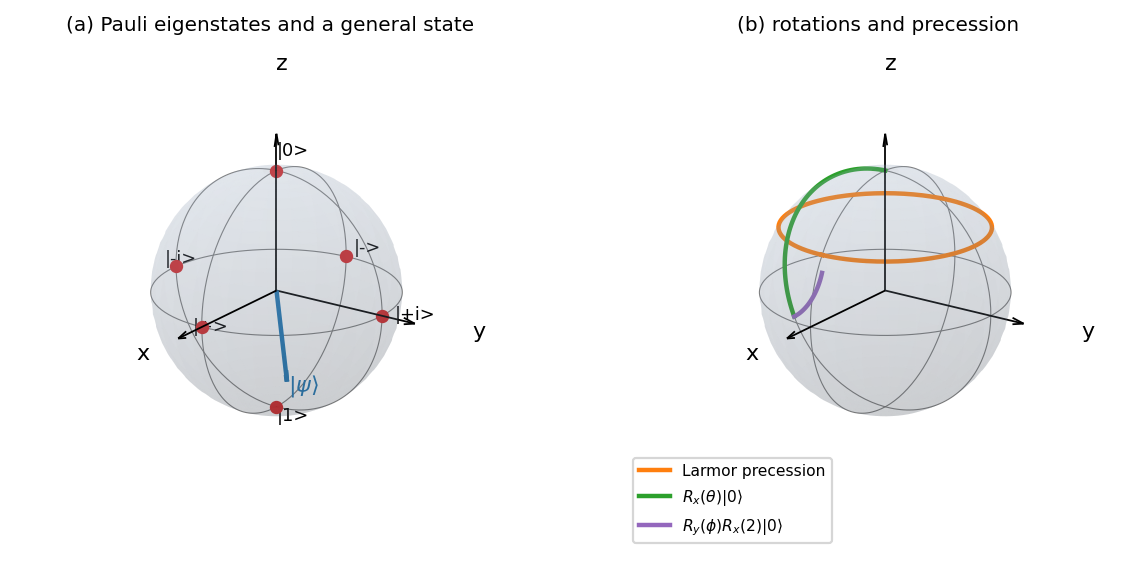

In [15]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/bloch_sphere.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


outcome 0: probability 0.3000, post-measurement state [1.+0.j 0.+0.j]
outcome 1: probability 0.7000, post-measurement state [0.    +0.j     0.9211+0.3894j]
Tr(P_0 rho) = 0.29999999999999993
<Z> = p0 - p1 = -0.40000000000000013   <X> = 0.8441663449378976
P(+) = |<+|psi>|^2 = 0.9221 = P(0) after H = 0.9221
P(qubit 1 = 0), P(qubit 1 = 1) in |Psi> = [0.5 0.5]
after finding qubit 1 = 1 the register is (+0.8525+0.0000j)|110> + (+0.5227+0.0000j)|111>


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter2/measurement_shots.pdf


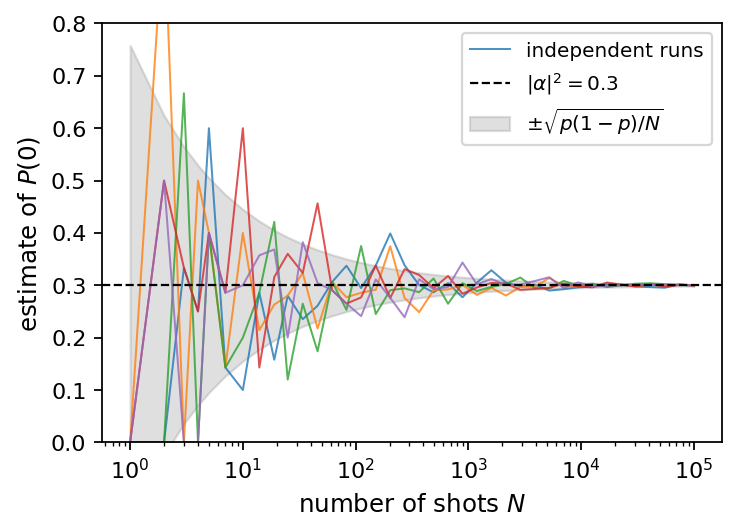

In [16]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/measurement.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


rho(|+>) after one dephasing step with p = 0.1:
 [[0.5 0.4]
 [0.4 0.5]]
step   purity (dephasing)   purity (damping)  <Z> (damping)
   0               1.0000             1.0000         0.0000
   5               0.6743             0.8877         0.3409
  10               0.5608             0.8772         0.5656
  20               0.5074             0.9235         0.8113
  30               0.5009             0.9624         0.9180


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter2/decoherence.pdf


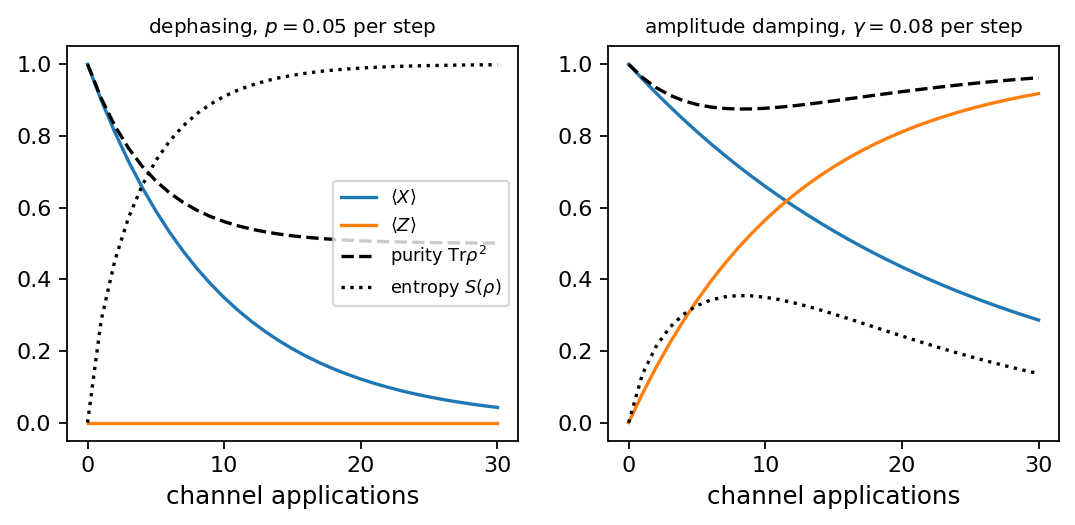

In [17]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/decoherence.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Bell states form an orthonormal basis: Gram matrix =
 [[ 1. -0.  0.  0.]
 [-0.  1.  0.  0.]
 [ 0.  0.  1. -0.]
 [ 0.  0. -0.  1.]]
qubit A = 0 with probability 0.50; state afterwards (+1.0000+0.0000j)|00>
qubit A = 1 with probability 0.50; state afterwards (+1.0000+0.0000j)|11>

state                       rho_A   purity  S(rho_A)     Schmidt coeffs
Phi+     [[0.5, 0.0], [0.0, 0.5]]    0.500     1.000   [0.7071, 0.7071]
Phi-     [[0.5, 0.0], [0.0, 0.5]]    0.500     1.000   [0.7071, 0.7071]
Psi+     [[0.5, 0.0], [0.0, 0.5]]    0.500     1.000   [0.7071, 0.7071]
Psi-     [[0.5, 0.0], [0.0, 0.5]]    0.500     1.000   [0.7071, 0.7071]

product state: Schmidt rank 1 , S(rho_A) = 0.0
random state: Schmidt coefficients [0.9863 0.1647] -> S(rho_A) = 0.1798 bit

theta/pi  S(rho_A)
    0.00    0.0000
    0.05    0.1659
    0.10    0.4545
    0.15    0.7340
    0.20    0.9300
    0.25    1.0000
    0.30    0.9300
    0.35    0.7340
    0.40    0.4545
    0.45    0.1659
    0.50    0.0000


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter2/entropy.pdf


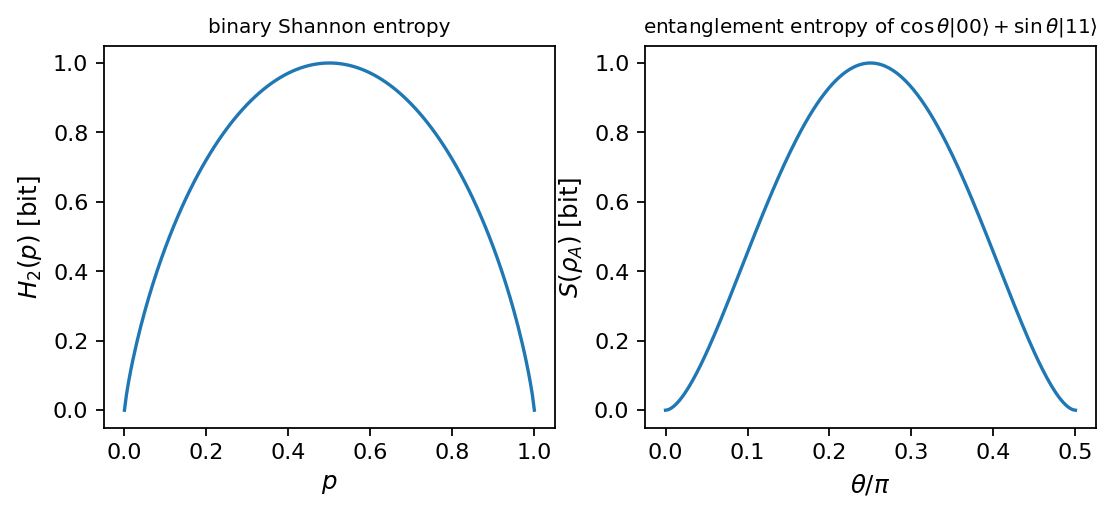

In [18]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/entanglement.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


In [19]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/protocols.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


superdense coding:
  Alice sends 00 -> Bob reads 00
  Alice sends 01 -> Bob reads 01
  Alice sends 10 -> Bob reads 10
  Alice sends 11 -> Bob reads 11

teleportation:
  200 random states teleported exactly; outcomes of Alice's measurement: {(0, 0): 44, (0, 1): 46, (1, 0): 53, (1, 1): 57}
  input state [0.8253+0.j     0.351 +0.4423j] -> Alice's bits (0, 0) -> Bob's Bloch vector [0.5794 0.7301 0.3624]

teleportation circuit before the measurements:
q0: |0>-----------*--[H]--
q1: |0>--[H]--*--(+)------
q2: |0>------(+)----------


lambda = 1.0: eigenvalues [0.9802 3.0198]
ground state [ 0.0985+0.j -0.9951+0.j], |0>-component squared 0.0097

 lambda       E_0       E_1  |<0|E_0>|^2
  0.000    0.0000    4.0000       1.0000
  0.300    0.8984    3.1016       0.9993
  0.600    1.7668    2.2332       0.9287
  0.667    1.8667    2.1333       0.5000
  0.700    1.8280    2.1720       0.2094
  1.000    0.9802    3.0198       0.0097

single ansatz theta=pi/2, phi=0.2pi: E = 2.0000
best grid point: theta = 170 deg, phi = 10 deg, E = 0.9960, E - E_0 = 0.0158


one-degree grid: theta = 180 deg, phi = 11 deg, E - E_0 = 1.49e-05


figure written to /home/claude/qcbook/doc/Book/BookFigures/chapter2/two_level_system.pdf


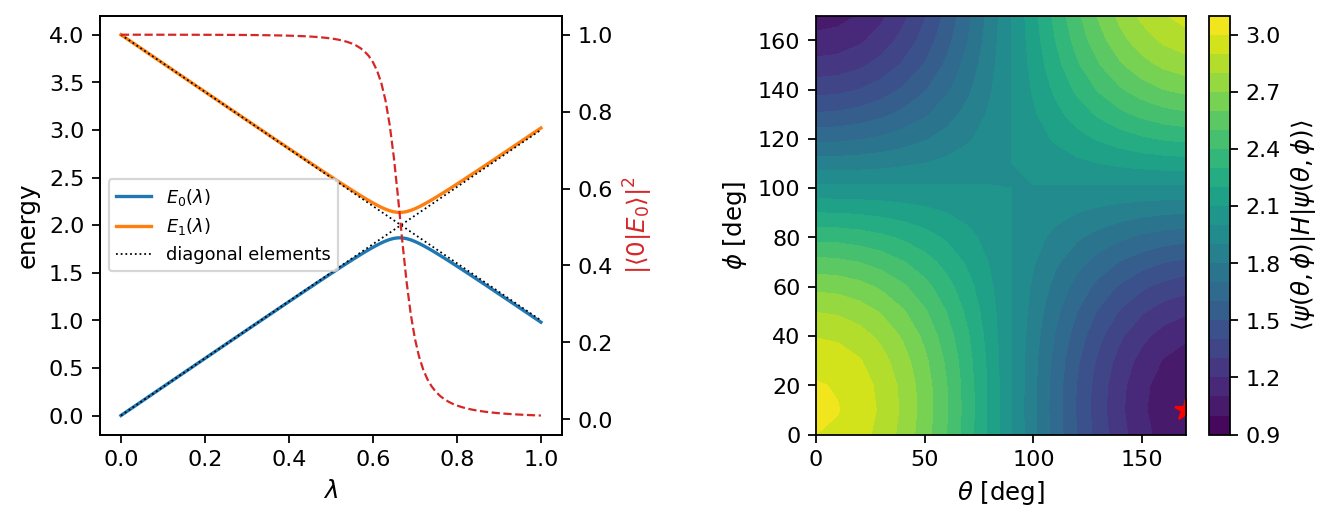

In [20]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter2/two_level_system.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter2').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
